# Python包准备

数据分析与建模必备的几个包： `numpy`, `pandas`, `sklearn`, `matplotlib`. 

数据分析与建模必备的几个包： `numpy`, `pandas`, `sklearn`, `matplotlib`. 

In [1]:
# numpy和pandas用于做数据处理
import numpy as np
import pandas as pd 

# 系统工具
import os  # os用于做文件系统管理 
import datetime
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# matplotlib和seaborn用于画图 
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
color = sns.color_palette()

# sklearn用于机器学习建模
from sklearn.preprocessing import LabelEncoder ## sklearn下的preprocessing用于处理类别变量 
from sklearn.preprocessing import MinMaxScaler

from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2
 
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, log_loss, confusion_matrix  

# 其他模型
import xgboost as xgb
import lightgbm as lgb
from datetime import datetime

# from catboost import CatBoostRegressor

In [2]:
need_imblearn = True #是否需要过采样

In [3]:
!python -V
!pip list

Python 3.8.16
Package                           Version
--------------------------------- ---------
aiohttp                           3.9.1
aiosignal                         1.3.1
anyio                             3.6.2
apache-beam                       2.38.0
apache-flink                      1.16.1
apache-flink-libraries            1.16.1
appnope                           0.1.3
argon2-cffi                       21.3.0
argon2-cffi-bindings              21.2.0
arrow                             1.2.3
asttokens                         2.2.1
async-lru                         2.0.4
async-timeout                     4.0.3
attrs                             22.2.0
avro-python3                      1.9.2.1
Babel                             2.14.0
backcall                          0.2.0
backports.functools-lru-cache     1.6.5
bayesian-optimization             1.4.3
beautifulsoup4                    4.12.3
bleach                            6.0.0
bs4                               0.0.2
cachetools

# 业务需求分析

* 分析业务需求
* 涉及到哪些数据表
* 根据已有数据信息，初步确定用什么模型来解决业务需求

# 看数、模型设计、拼表

在此部分，先初步地了解数据库中可以获得哪些数据，并根据数据的基本情况进行模型设计。

* 对已有数据进行初步探索，对每张数据表，根据数据字典做基本数据分析
    * 了解数据质量（数据是否可用、缺失值是否过多等）
    * 字段的分布情况
    
* 理清宽表的构成逻辑
    * 大概涉及多少张表
    * 表之间的关联id
    * 大致数量级
    
* 根据数据进行模型设计
    * 确定模型类别（分类、预测、异常检测、社交网络……等等）
    * 是否具备做监督学习的条件
    * y的定义是否涉及到属性变化
    * 属性变化的时间窗（观察期、表现期）
    
* 根据模型设计拼表
    * 注意避免笛卡尔积
    * 保证join字段唯一性
    * 尽量使用join，避免嵌套子循环

# 导入拼表

In [4]:
# 列出data文件夹下的所有数据 
# os.listdir()

**A total of 11162 rows and 17 columns of data are defined as follows:**

**共有11162行和17列数据，定义如下：**

**1.1 Basic attributes（基本属性）**

> age：年龄<p>
    > job：工作岗位<p>
       > marital：婚姻状态<p>
         > education：教育程度<p>
            > defalut：是否违约<p>
               > balance：盈余<p>
                 > housing：是否有住房贷款<p>
                    > loan：是否有个人贷款<p>
        
**1.2 Business contact（业务联系）**

> contact：联系方式<p> 
    >day:上一个联系日 <p>
        > month：上一个联系月<p>
            > duration：通话时间，秒<p>

**1.3 Marketing activities（营销活动）**
> 
> campain：上一次营销活动和此客户联系的次数<p>
    >pdays：自上一次营销活动联系后，至今的天数<p>
        >previous：上一次营销活动之前和客户累计联系过的次数<p>
            >poutcome：上一次营销的结果

**1.4 target data(目标数据)**
>deposit：客户是否有定期存款？

**数据集结构**

| Feature     | Description                                           |
|-------------|-------------------------------------------------------|
| age         | 年龄                                                  |
| job         | 工作                                                  |
| marital     | 婚姻状况                                              |
| education   | 教育水平                                              |
| default     | 是否有信用违约                                        |
| balance     | 账户余额                                              |
| housing     | 是否有住房贷款                                        |
| loan        | 是否有个人贷款                                        |
| contact     | 联系方式                                              |
| day         | 联系日期（一个月中的哪一天）                          |
| month       | 联系月份                                              |
| duration    | 上次联系持续时间（以秒为单位）                        |
| campaign    | 本次活动期间联系的次数                                 |
| pdays       | 距离上次活动联系的天数（-1 表示之前没有联系过）       |
| previous    | 上次活动期间联系的次数                                 |
| poutcome    | 上次活动的结果                                        |
| deposit     | 是否订购定期存款（目标变量）                          |

**特征加工**

基于原始特征，我们可以生成一些衍生特征，以帮助模型更好地捕捉数据中的模式。这些特征包括窗口特征、时序特征、统计特征和业务含义特征等。

**窗口特征**

1. **最近一次联系的月份数**
    - 使用 `month` 特征可以将月份转换为数字表示，并计算到当前月份的时间差。
    ```python
    import pandas as pd
    from datetime import datetime

    df['month_num'] = pd.to_datetime(df['month'], format='%b').dt.month
    df['days_since_contact'] = (datetime.now() - pd.to_datetime(df['day'], format='%d')).dt.days
    ```

2. **滚动窗口联系次数**
    - 计算一定时间窗口内的总联系次数，如过去3个月的联系次数。
    ```python
    df['contact_last_3_months'] = df.groupby('customer_id')['contact'].rolling(3).sum().reset_index(drop=True)
    ```

**时序特征**

1. **联系的时间间隔**
    - 计算两次联系之间的时间间隔。
    ```python
    df['days_since_last_contact'] = df['pdays'].apply(lambda x: x if x != -1 else None)
    ```

**统计特征**

1. **账户余额的统计特征**
    - 计算账户余额的均值、中位数、标准差等。
    ```python
    df['balance_mean'] = df.groupby('customer_id')['balance'].transform('mean')
    df['balance_median'] = df.groupby('customer_id')['balance'].transform('median')
    df['balance_std'] = df.groupby('customer_id')['balance'].transform('std')
    ```

2. **联系次数的统计特征**
    - 计算不同时间段内的联系次数统计特征。
    ```python
    df['campaign_mean'] = df.groupby('customer_id')['campaign'].transform('mean')
    df['campaign_std'] = df.groupby('customer_id')['campaign'].transform('std')
    ```

**业务含义特征**

1. **是否有任何贷款**
    - 判断客户是否有任何类型的贷款（住房贷款或个人贷款）。
    ```python
    df['has_any_loan'] = df.apply(lambda x: 'yes' if x['housing'] == 'yes' or x['loan'] == 'yes' else 'no', axis=1)
    ```

2. **上次活动的成功率**
    - 计算上次活动期间的成功率。
    ```python
    df['previous_success_rate'] = df.groupby('customer_id')['poutcome'].apply(lambda x: (x == 'success').sum() / len(x))
    ```

**特征加工后的数据框架**

| Feature               | Description                                           |
|-----------------------|-------------------------------------------------------|
| age                   | 年龄                                                  |
| job                   | 工作                                                  |
| marital               | 婚姻状况                                              |
| education             | 教育水平                                              |
| default               | 是否有信用违约                                        |
| balance               | 账户余额                                              |
| housing               | 是否有住房贷款                                        |
| loan                  | 是否有个人贷款                                        |
| contact               | 联系方式                                              |
| day                   | 联系日期（一个月中的哪一天）                          |
| month                 | 联系月份                                              |
| duration              | 上次联系持续时间（以秒为单位）                        |
| campaign              | 本次活动期间联系的次数                                 |
| pdays                 | 距离上次活动联系的天数（-1 表示之前没有联系过）       |
| previous              | 上次活动期间联系的次数                                 |
| poutcome              | 上次活动的结果                                        |
| deposit               | 是否订购定期存款（目标变量）                          |
| month_num             | 联系月份的数字表示                                    |
| days_since_contact    | 距离最近一次联系的天数                                 |
| contact_last_3_months | 过去3个月的联系次数                                   |
| days_since_last_contact | 距离上次联系的天数（忽略 -1）                        |
| balance_mean          | 账户余额的均值                                        |
| balance_median        | 账户余额的中位数                                      |
| balance_std           | 账户余额的标准差                                      |
| campaign_mean         | 本次活动期间联系次数的均值                             |
| campaign_std          | 本次活动期间联系次数的标准差                           |
| has_any_loan          | 是否有任何类型的贷款（住房贷款或个人贷款）            |
| previous_success_rate | 上次活动期间的成功率                                  |

In [5]:
# 读取数据
df = pd.read_csv('银行营销响应数据集（认购存款）.csv')
print('数据信息: ', df.shape)
df['deposit'] = df['deposit'].str.lower().replace({'no': 0, 'yes': 1})
df = df.rename(columns = {'deposit':'TARGET'})
df.head()

数据信息:  (11162, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,TARGET
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,1
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,1
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,1
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,1
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,1


# 探索性数据分析EDA

## 数据整体分析

### 数据以及变量总况

针对已经拼好的宽表，读取数据以查看数据总况：
- 几行几列：几行代表多少样本；几列代表多少特征
- 变量结构：找出目标变量、连续性变量、分类变量等
- 变量意义以及取值

In [6]:
# 几行几列
print(f'{df.shape[0]}个观测值')
print(f'{df.shape[1]}个变量（包括目标变量）')

11162个观测值
17个变量（包括目标变量）


In [7]:
#查看列名称，目标变量是TARGET
df.columns.values  

array(['age', 'job', 'marital', 'education', 'default', 'balance',
       'housing', 'loan', 'contact', 'day', 'month', 'duration',
       'campaign', 'pdays', 'previous', 'poutcome', 'TARGET'],
      dtype=object)

In [8]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous,TARGET
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557,0.473840
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007,0.499338
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000,1.000000


**客户平均年龄41岁左右，最高95岁，最低18岁；**
  
**平均客户盈余为1528，但标准差非常大，说明这一数据的分布非常分散。**
  
**上一次营销活动中的联系次数为1-63次，对应的联系次数越多，客户对上一次活动的参与度越高；**
  
**上次营销活动后的天数为-1~854天。为什么有-1？是否数据错误；**

**上次营销活动前与客户的累计接触次数为0~58次**

In [9]:
# 连续性变量、分类变量各有多少
 
# 数值型特征
numerical_fea = list(df.select_dtypes(exclude=['object']).columns)
# 分类型特征
category_fea = list(filter(lambda x: x not in numerical_fea,list(df.columns)))
#category_fea = list(data_train.select_dtypes(include = ['object']).columns)

In [10]:
# 将特征按object，number类型进行分类；numberical_fea为数值型特征，category_fea为对象特征
numerical_fea = list(df.select_dtypes(exclude=['object']).columns)
category_fea = list(filter(lambda x: x not in numerical_fea,list(df.columns)))
# category_fea = list(data_train.select_dtypes(include = ['object']).columns)

In [11]:
# 查看训练集中变量的类型各有多少 
df.dtypes.value_counts()  

object    9
int64     8
Name: count, dtype: int64

### 数据质量检查

* 数据去重: 拼表可能会有数据重复、冲突的问题。利用df[var].value_counts()来检查表中唯一标识的字段是否有重复情况，如有，需做进一步的修正。

* 数据变量初选：剔除无效变量：
将唯一标识类、单一取值类等不可用变量做初步剔除。

* 变量属性转换：
检查变量的属性是否有明显错误

* 数据填充：
将可补0的缺失值进行补0

* 训练集和待预测集的数据分布情：检查不同数据集中同一个变量的取值分布（尤其是类别性变量）的取值是否一致，避免后期建模预测时出现维度不一致的问题。

#### 无效变量

In [12]:
# 查看训练集测试集中特征属性只有一值的特征
one_value_fea = [col for col in df.columns if df[col].nunique() <=1]
print(f'There are {len(one_value_fea)} columns {one_value_fea} in train dataset with one unique value') 

There are 0 columns [] in train dataset with one unique value


#### 类型错误变量

In [13]:
# 过滤数值型类别特征: 有些变量（尤其是标识类）虽然是数值型，但应该归为类别型。
def get_numerical_serial_fea(data,feas):
    numerical_serial_fea = []
    numerical_noserial_fea = []
    for fea in feas:
        temp = data[fea].nunique()
        if temp <= 10:
            numerical_noserial_fea.append(fea)
            continue
        numerical_serial_fea.append(fea)
    return numerical_serial_fea,numerical_noserial_fea

numerical_serial_fea,numerical_noserial_fea = get_numerical_serial_fea(df,numerical_fea)

In [14]:
numerical_serial_fea

['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

In [15]:
numerical_noserial_fea

['TARGET']

#### 缺失值

In [16]:
# 首先定义缺失值计算的函数 
def missing_values_table(df):
        # 计算所有的缺失值 
        mis_val = df.isnull().sum()
        
        # 计算缺失值的比例 
        mis_val_percent = 100 * df.isnull().sum() / len(df)
        
        # 将结果用table呈现 
        mis_val_table = pd.concat([mis_val, mis_val_percent], axis=1)
        
        # table里的列重新命名
        mis_val_table_ren_columns = mis_val_table.rename(
        columns = {0 : 'Missing Values', 1 : '% of Total Values'})
        
        # 将table根据缺失值比例排序显示 
        mis_val_table_ren_columns = mis_val_table_ren_columns[
            mis_val_table_ren_columns.iloc[:,1] != 0].sort_values(
        '% of Total Values', ascending=False).round(1)
        
        # 打印结果 
        print ("数据集共有" + str(df.shape[1]) + "列。\n其中"      
             + str(mis_val_table_ren_columns.shape[0]) +
              "列有缺失值。")
        
        # 返回结果 
        return mis_val_table_ren_columns

In [17]:
# 调用函数
missing_values = missing_values_table(df)
missing_values

数据集共有17列。
其中0列有缺失值。


,Missing Values,% of Total Values


#### 异常值

- 打字错误
- 测量错误
- 其他

In [18]:
# 举例：营销天数-1不符合常理
(df['pdays']).describe()

count    11162.000000
mean        51.330407
std        108.758282
min         -1.000000
25%         -1.000000
50%         -1.000000
75%         20.750000
max        854.000000
Name: pdays, dtype: float64

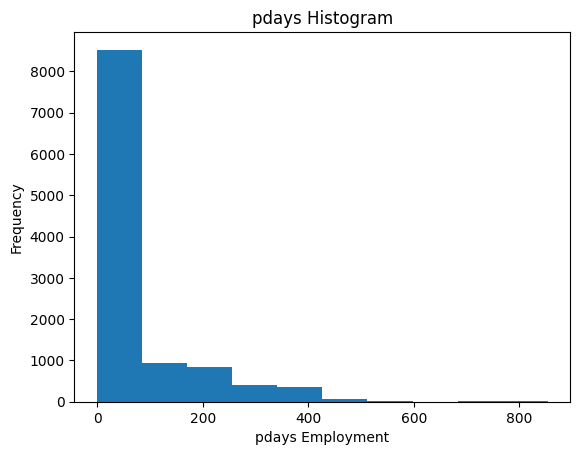

In [19]:
df['pdays'].plot.hist(title = 'pdays Histogram');
plt.xlabel('pdays Employment');

In [20]:
anom = df[df['pdays'] == -1] # 异常值
non_anom = df[df['pdays'] != -1] # 正常的

In [21]:
anom_rate = 100 * non_anom['TARGET'].mean()
anom_rate

67.1247357293869

In [22]:
non_anom_rate = 100 * anom['TARGET'].mean()
non_anom_rate

40.653531955790484

- 异常数据部分的平均响应率：67.1247357293869%
- 非异常数据部分的平均响应率：40.653531955790484%

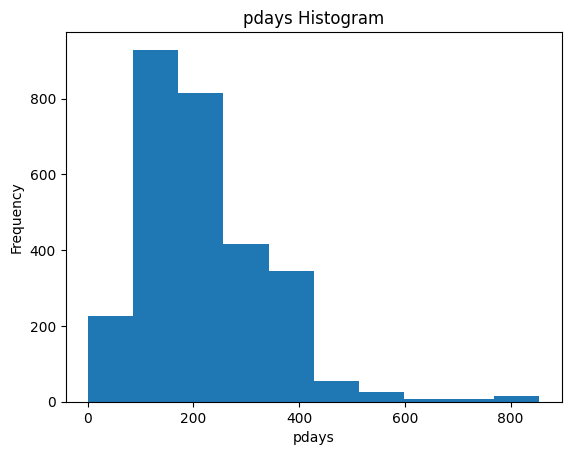

In [23]:
# Create an anomalous flag column
df['pdays_ANOM'] = df["pdays"] == -1

# Replace the anomalous values with nan
df['pdays'].replace({-1: np.nan}, inplace = True)

df['pdays'].plot.hist(title = 'pdays Histogram');
plt.xlabel('pdays');

In [24]:
# 均方差检测异常: 68% 的数据值会在均值的一个标准差范围内，大约 95% 会在两个标准差范围内，大约 99.7% 会在三个标准差范围内。
def find_outliers_by_3segama(data, fea):
    # 计算标准差和均值
    data_std = np.std(data[fea])
    data_mean = np.mean(data[fea])
    
    # 计算上下界
    outliers_cut_off = data_std * 3
    lower_rule = data_mean - outliers_cut_off
    upper_rule = data_mean + outliers_cut_off
    
    # 标记异常值
    data[fea + '_outliers'] = data[fea].apply(lambda x: '异常值' if x > upper_rule or x < lower_rule else '正常值')
    
    return data

In [25]:
# 得到特征的异常值后可以进一步分析变量异常值和目标变量的关系
for col in numerical_serial_fea:
    data_outfier = find_outliers_by_3segama(df,col)
data_outfier.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,...,poutcome,TARGET,pdays_ANOM,age_outliers,balance_outliers,day_outliers,duration_outliers,campaign_outliers,pdays_outliers,previous_outliers
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,...,unknown,1,True,正常值,正常值,正常值,正常值,正常值,正常值,正常值
1,56,admin.,married,secondary,no,45,no,no,unknown,5,...,unknown,1,True,正常值,正常值,正常值,异常值,正常值,正常值,正常值
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,...,unknown,1,True,正常值,正常值,正常值,正常值,正常值,正常值,正常值
3,55,services,married,secondary,no,2476,yes,no,unknown,5,...,unknown,1,True,正常值,正常值,正常值,正常值,正常值,正常值,正常值
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,...,unknown,1,True,正常值,正常值,正常值,正常值,正常值,正常值,正常值


## 单变量分析

### 连续变量

In [26]:
df.describe() 

,age,balance,day,duration,campaign,pdays,previous,TARGET
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,2838.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,204.818182,0.832557,0.473840
std,11.913369,3225.413326,8.420740,347.128386,2.722077,122.196901,2.292007,0.499338
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,1.000000,0.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,98.000000,0.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,182.000000,0.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,286.000000,1.000000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000,1.000000


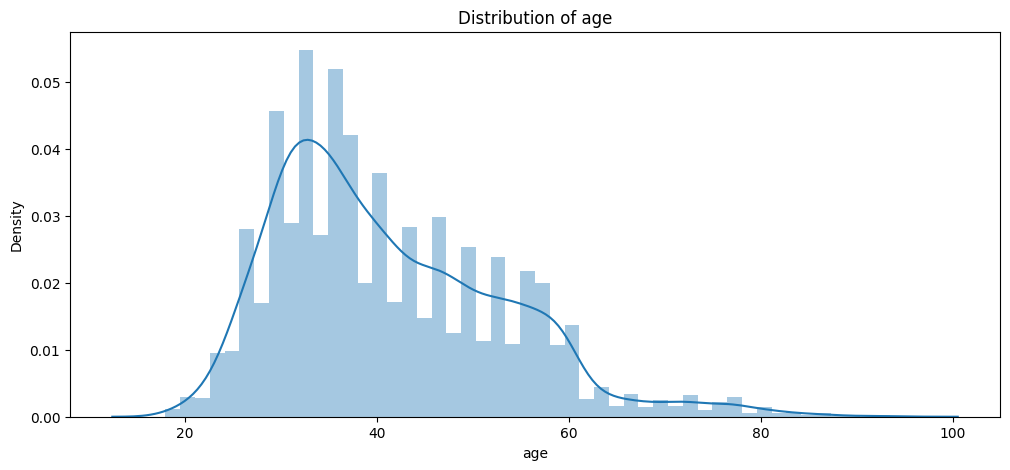

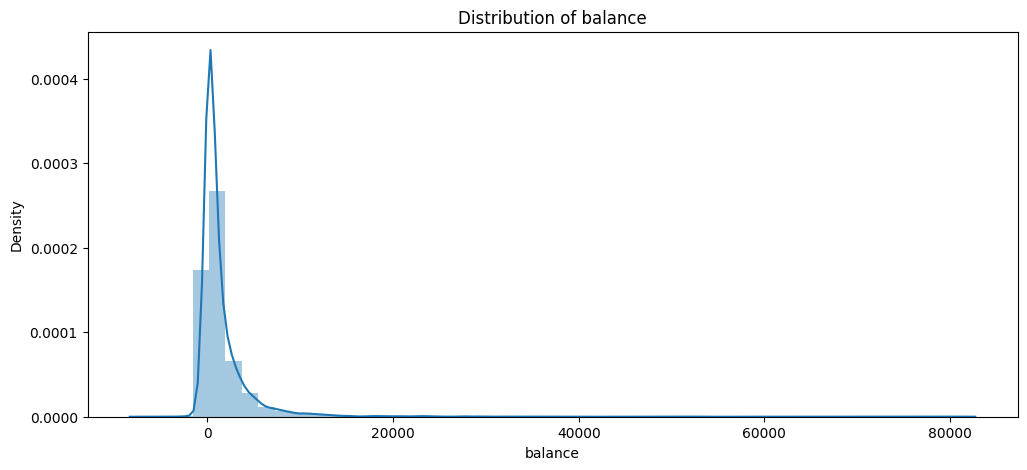

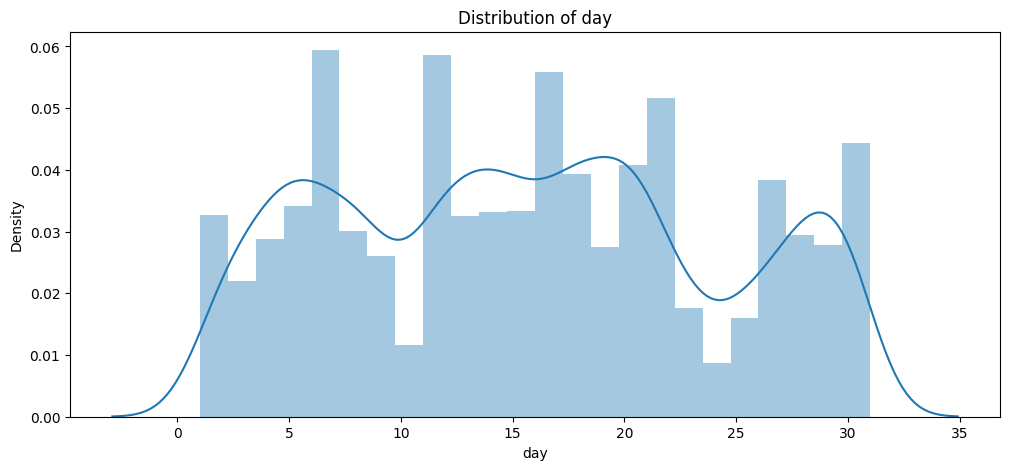

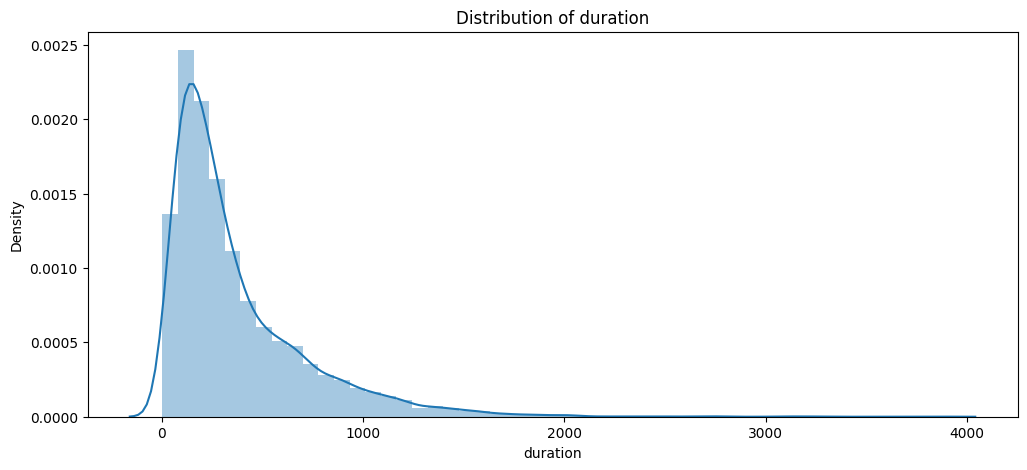

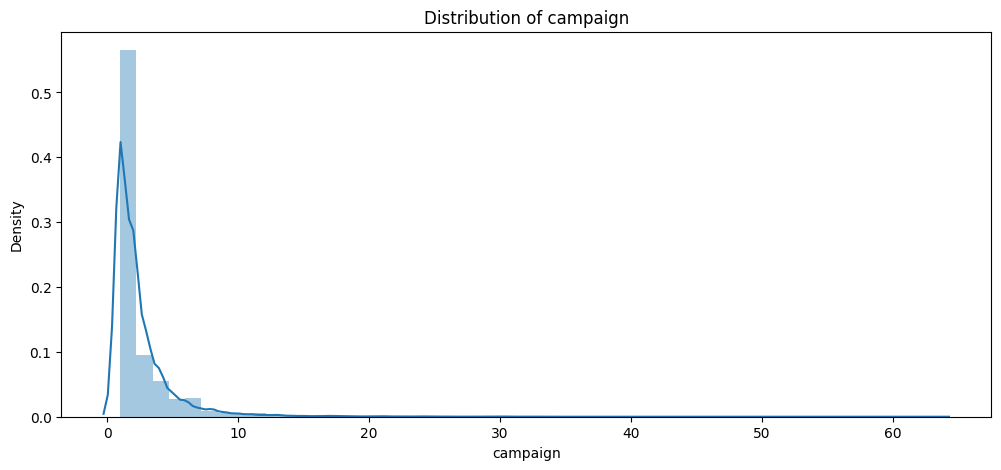

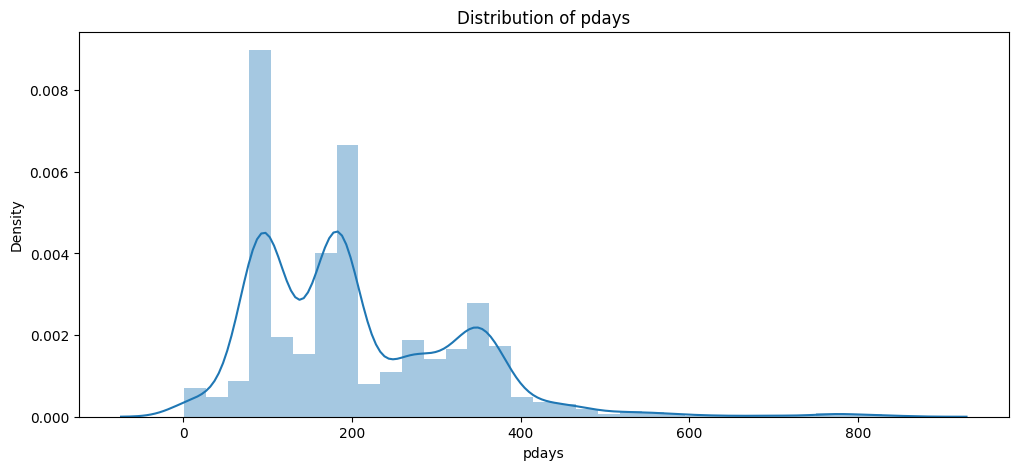

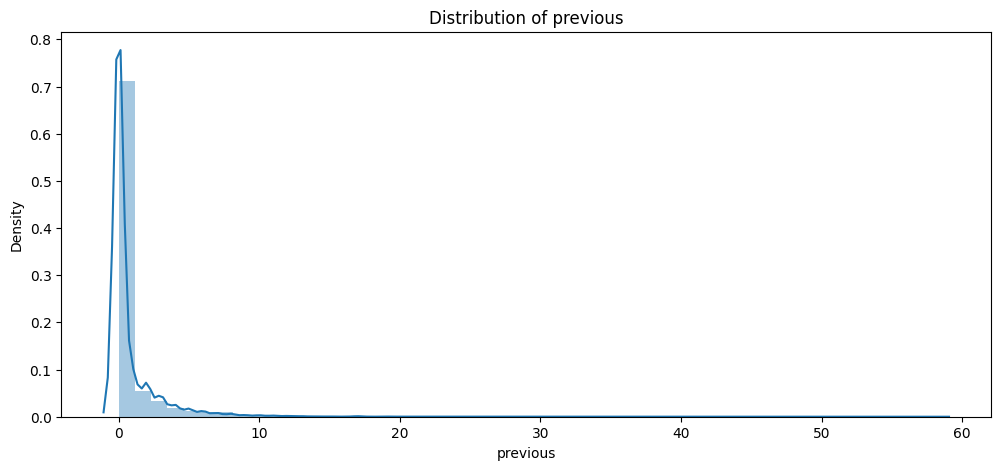

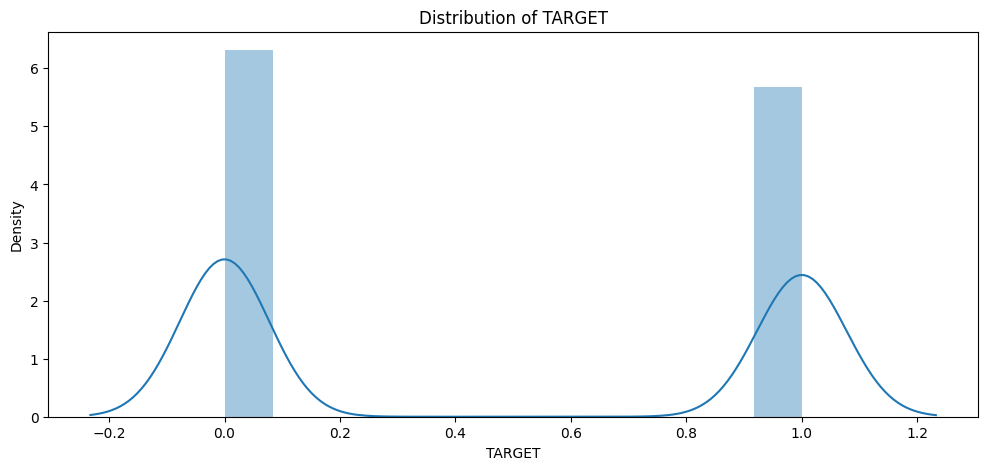

In [27]:
for i in numerical_fea:
    plt.figure(figsize=(12,5)) 
    plt.title("Distribution of " + str(i))
    ax = sns.distplot(df[i])

### 类别变量

In [28]:
# 查看类别变量的取值情况
df.select_dtypes('object').apply(pd.Series.nunique, axis = 0)

job                  12
marital               3
education             4
default               2
housing               2
loan                  2
contact               3
month                12
poutcome              4
age_outliers          2
balance_outliers      2
day_outliers          1
duration_outliers     2
campaign_outliers     2
pdays_outliers        2
previous_outliers     2
dtype: int64

In [29]:
for i in df.select_dtypes('object').columns:
    print('------------------------------------------------------')
    print(f'变量 {i} 的所有取值：')
    print('------------------------------------------------------')
    print(df[i].value_counts())
    print('\n')

------------------------------------------------------
变量 job 的所有取值：
------------------------------------------------------
job
management       2566
blue-collar      1944
technician       1823
admin.           1334
services          923
retired           778
self-employed     405
student           360
unemployed        357
entrepreneur      328
housemaid         274
unknown            70
Name: count, dtype: int64


------------------------------------------------------
变量 marital 的所有取值：
------------------------------------------------------
marital
married     6351
single      3518
divorced    1293
Name: count, dtype: int64


------------------------------------------------------
变量 education 的所有取值：
------------------------------------------------------
education
secondary    5476
tertiary     3689
primary      1500
unknown       497
Name: count, dtype: int64


------------------------------------------------------
变量 default 的所有取值：
----------------------------------------------------

### 目标变量

主要是看是否均衡

In [30]:
df['TARGET'].value_counts() 

TARGET
0    5873
1    5289
Name: count, dtype: int64

In [31]:
正样本比例 = df['TARGET'].value_counts()[1]/(df['TARGET'].value_counts()[0]+df['TARGET'].value_counts()[1])
print(f'正样本比例：{正样本比例}')

正样本比例：0.4738398136534671


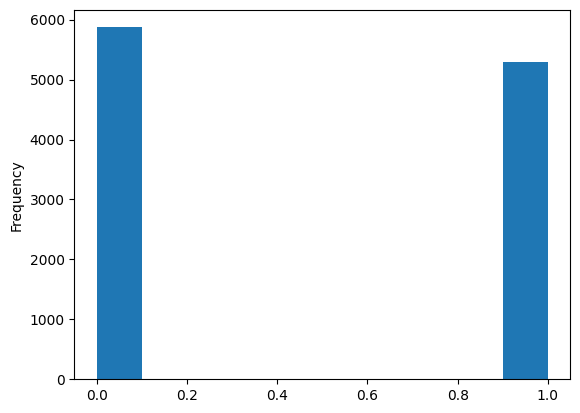

In [32]:
# 目标变量的分布图
df['TARGET'].astype(int).plot.hist();

## 变量间关系分析

对于有些模型，可能对变量之间的关系（是否变量之间相关性高、共线性等）有严格要求，因此需要对相关性高的变量做一定筛选。

### 特征VS特征：相关系数矩阵

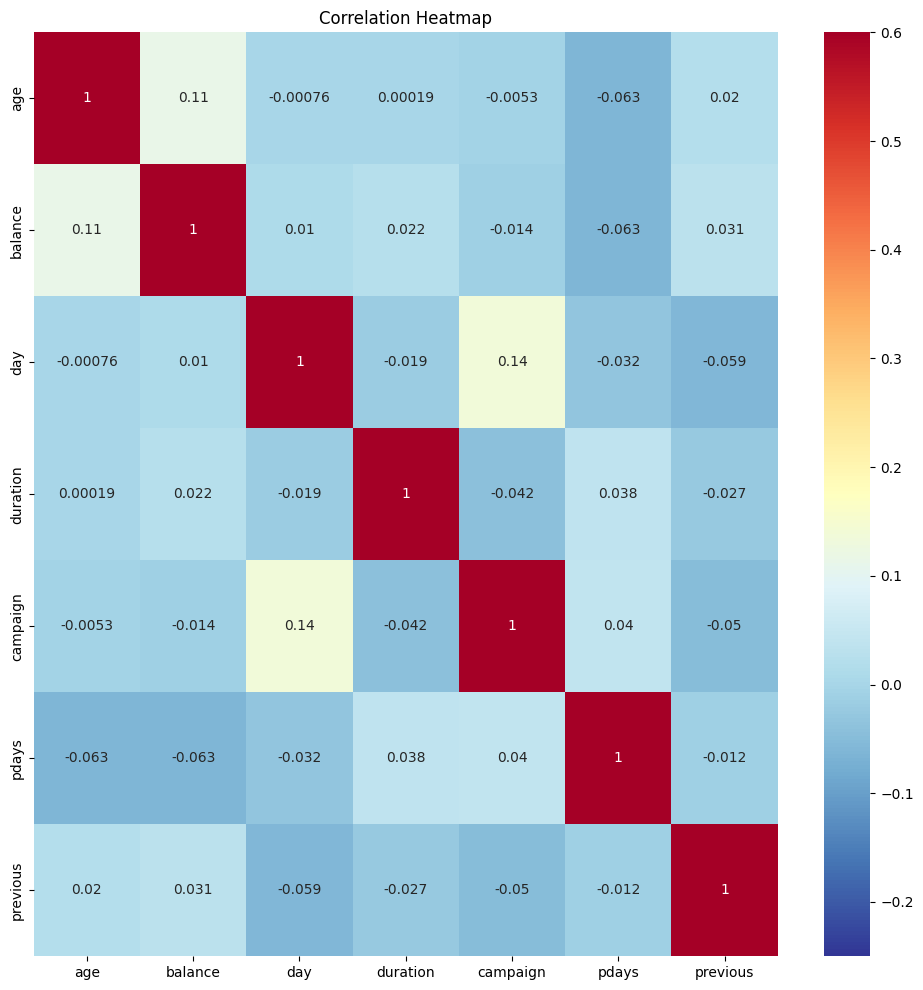

In [33]:
# 变量之间
cols = [i for i in numerical_serial_fea if i != 'TARGET']
df_corr = df[cols].corr()

# 画出相关系数矩阵
plt.figure(figsize = (12, 12)) # 创建一个12 * 12 大小的图
sns.heatmap(df_corr, cmap = plt.cm.RdYlBu_r, vmin = -0.25, annot = True, vmax = 0.6) #sns = seaborn 
plt.title('Correlation Heatmap');

### 特征 VS 目标

In [34]:
def plot_stats(feature,label_rotation=False,horizontal_layout=True):
    temp = df[feature].value_counts()
    df1 = pd.DataFrame({feature: temp.index,'Number of samples': temp.values})

    # Calculate the percentage of target=1 per category value
    cat_perc = df[[feature, 'TARGET']].groupby([feature],as_index=False).mean()
    cat_perc.sort_values(by='TARGET', ascending=False, inplace=True)
    
    if(horizontal_layout):
        fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,6))
    else:
        fig, (ax1, ax2) = plt.subplots(nrows=2, figsize=(12,14))
    sns.set_color_codes("pastel")
    s = sns.barplot(ax=ax1, x = feature, y="Number of samples",data=df1)
    if(label_rotation):
        s.set_xticklabels(s.get_xticklabels(),rotation=90)
    
    s = sns.barplot(ax=ax2, x = feature, y='TARGET', order=cat_perc[feature], data=cat_perc)
    if(label_rotation):
        s.set_xticklabels(s.get_xticklabels(),rotation=90)
    plt.ylabel('Percent of target with value 1 [%]', fontsize=10)
    plt.tick_params(axis='both', which='major', labelsize=10)

    plt.show();

In [35]:
def plot_distribution(var):
    
    i = 0
    t1 = df.loc[df['TARGET'] != 0]
    t0 = df.loc[df['TARGET'] == 0]

    sns.set_style('whitegrid')
    plt.figure()
    fig, ax = plt.subplots(2,2,figsize=(12,12))

    for feature in var:
        i += 1
        plt.subplot(2,2,i)
        sns.kdeplot(t1[feature], bw=0.5,label="TARGET = 1")
        sns.kdeplot(t0[feature], bw=0.5,label="TARGET = 0")
        plt.ylabel('Density plot', fontsize=12)
        plt.xlabel(feature, fontsize=12)
        locs, labels = plt.xticks()
        plt.tick_params(axis='both', which='major', labelsize=12)
    plt.show();

#### 类别变量 VS 目标变量

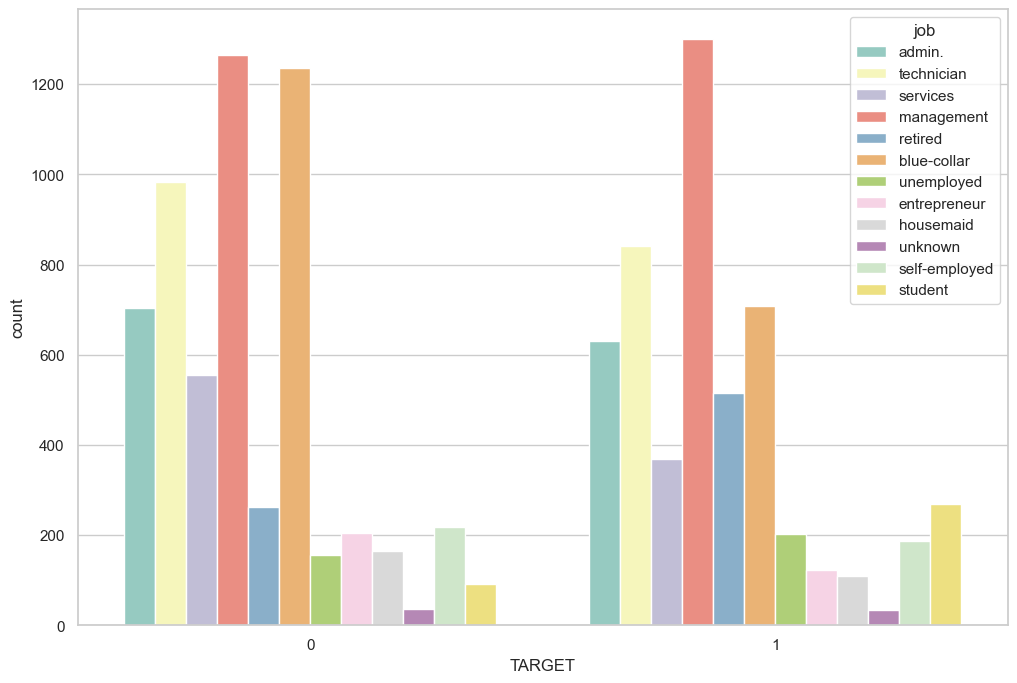

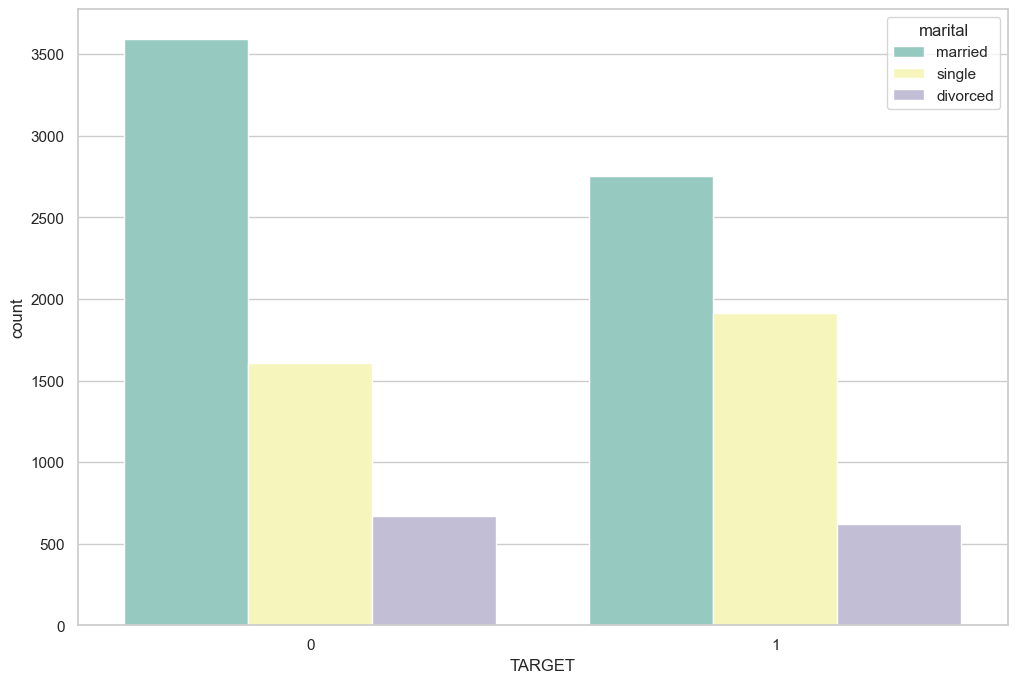

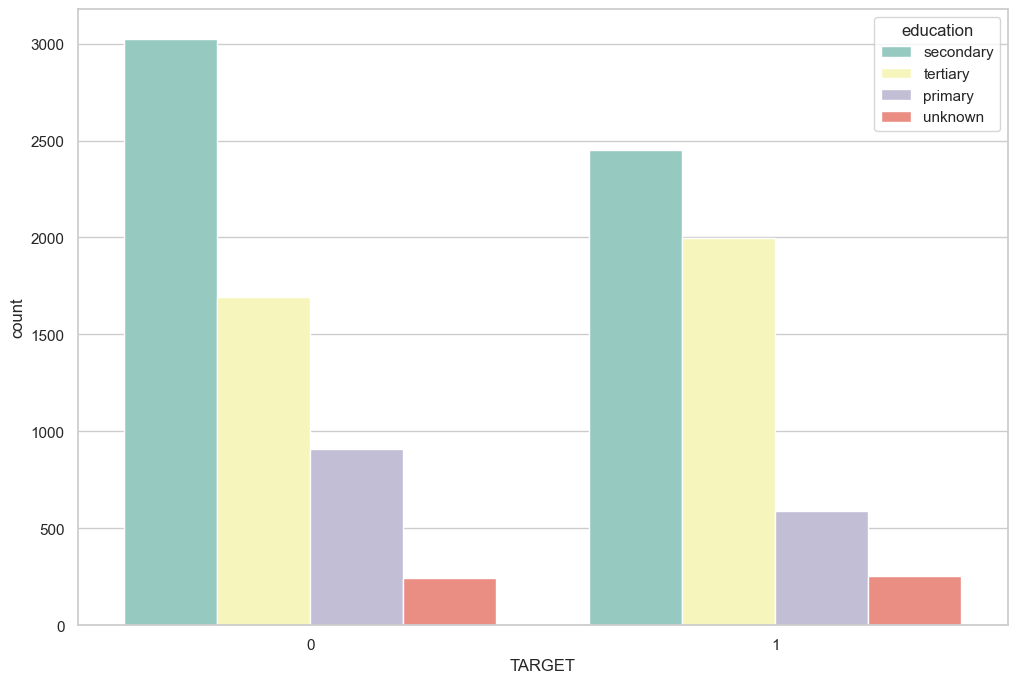

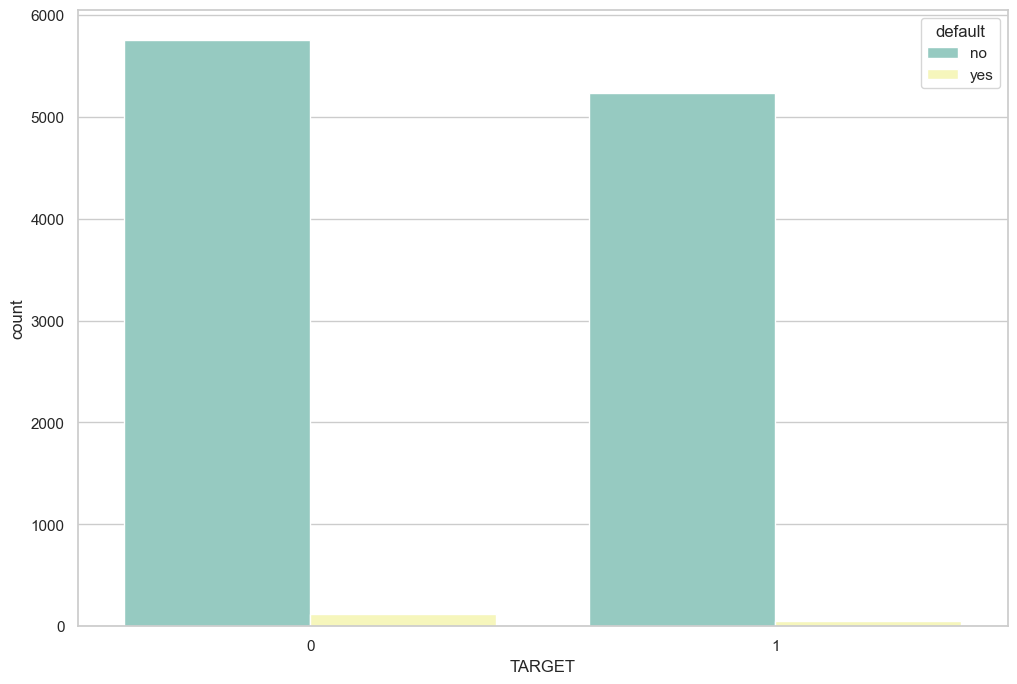

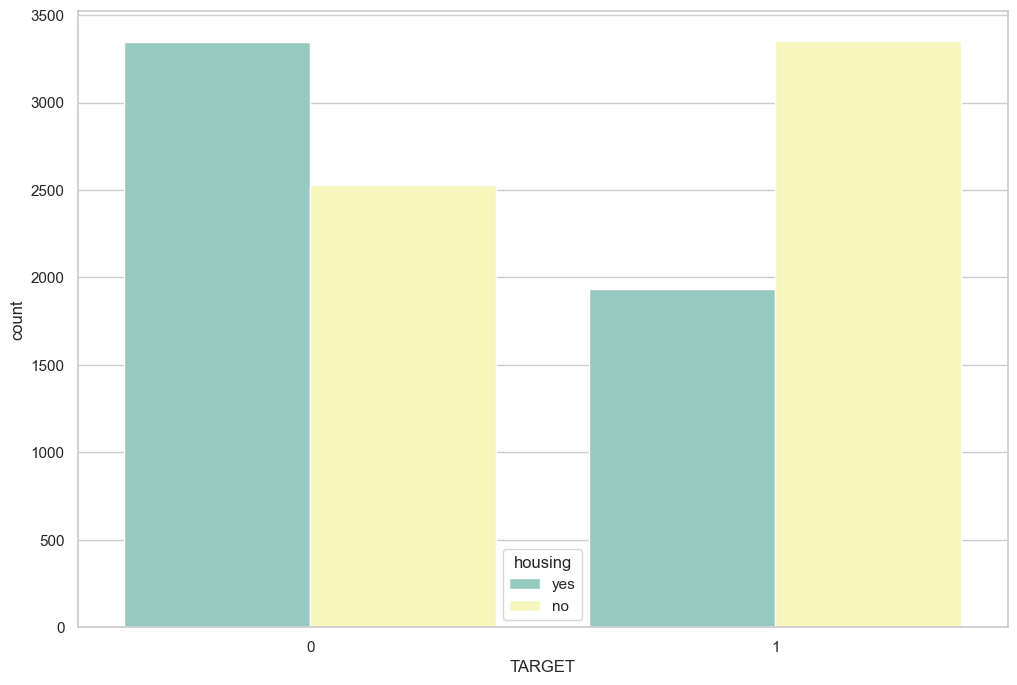

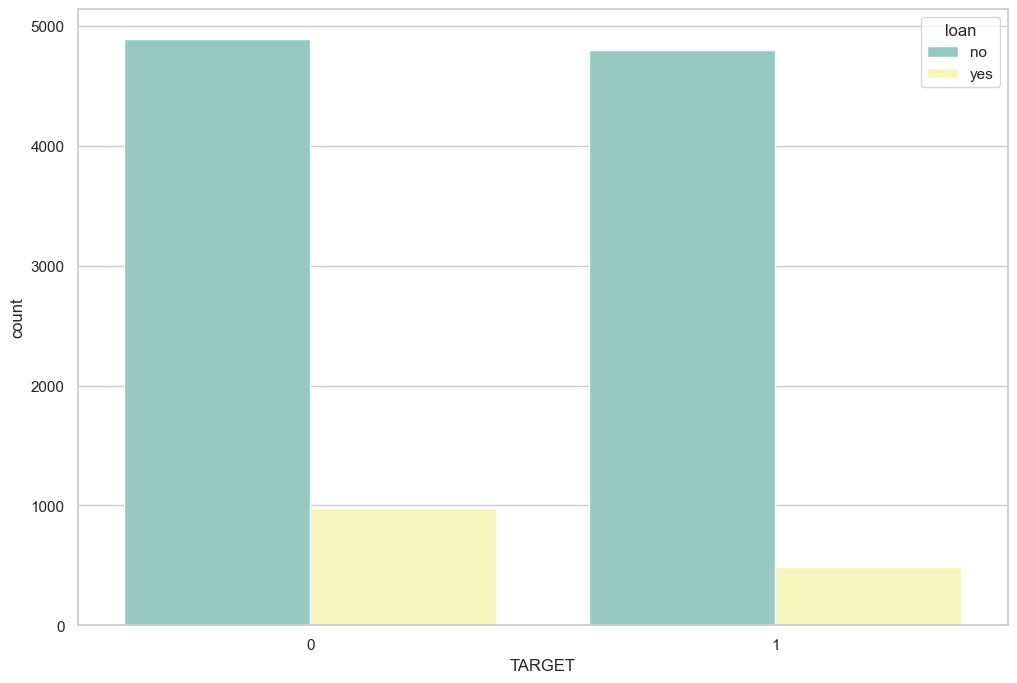

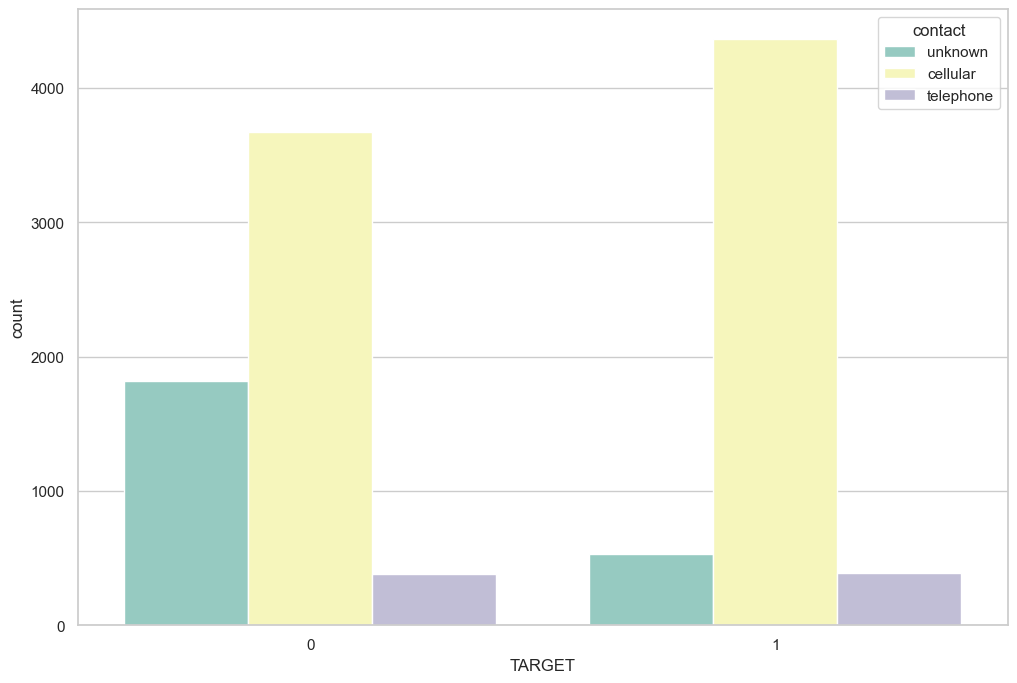

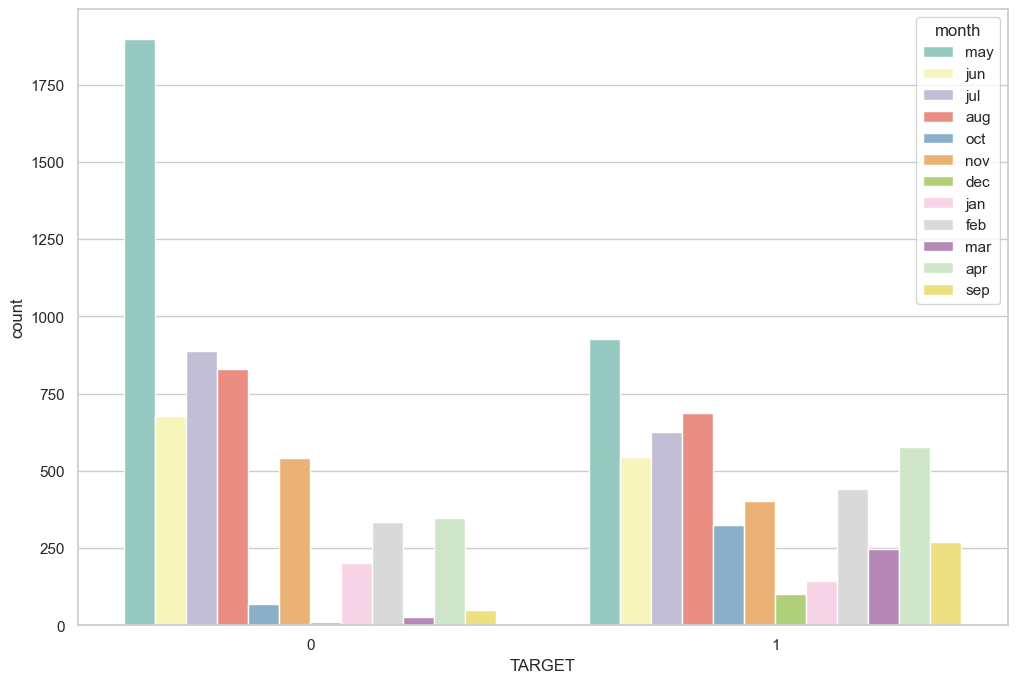

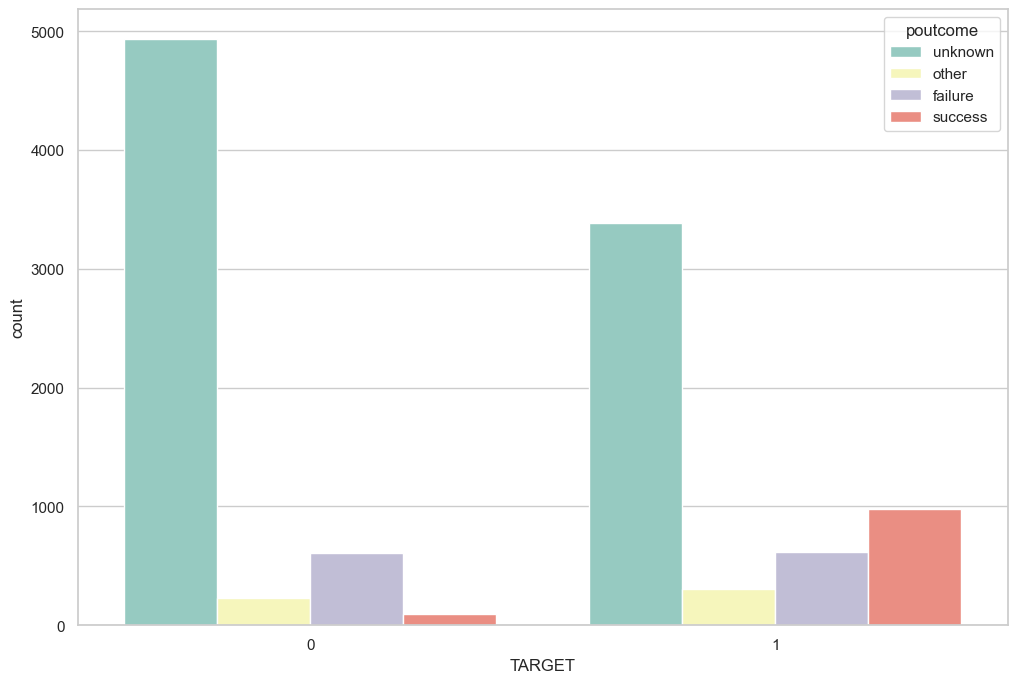

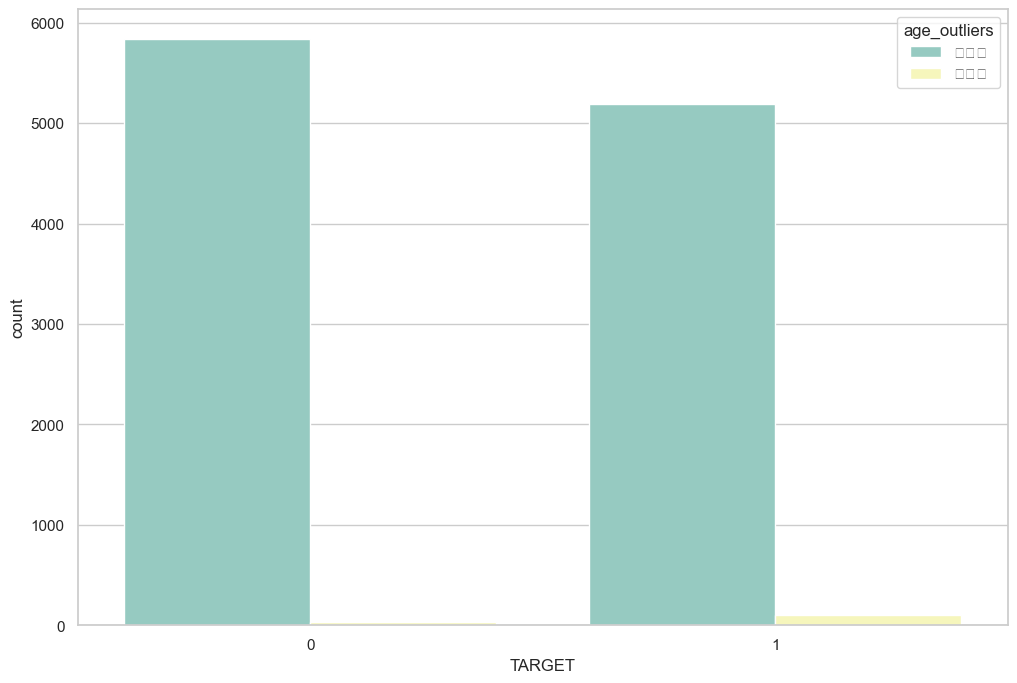

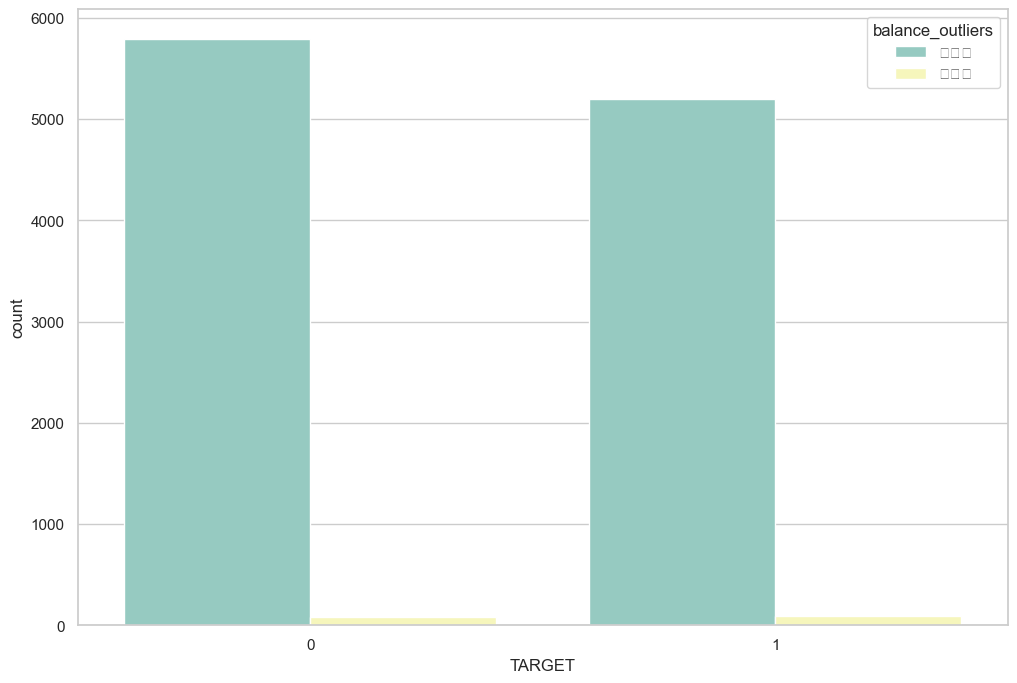

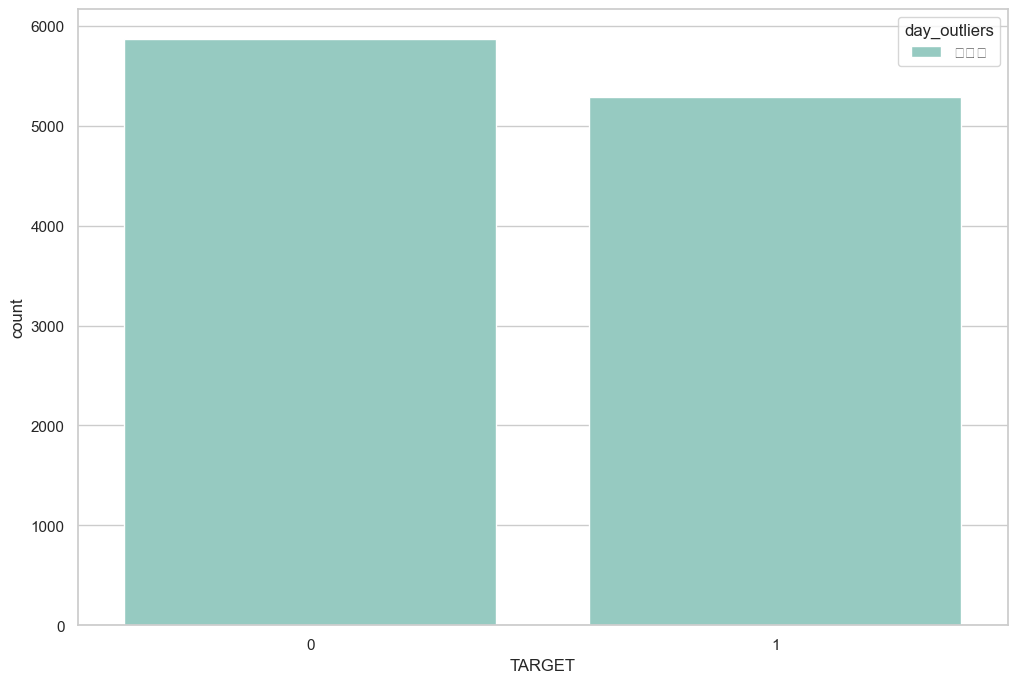

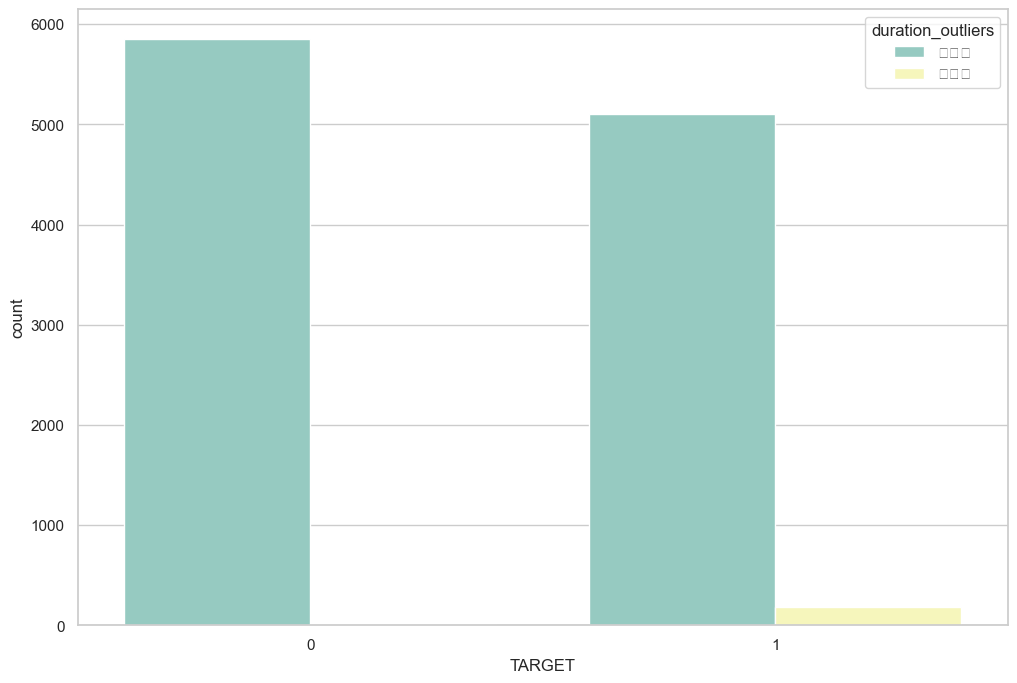

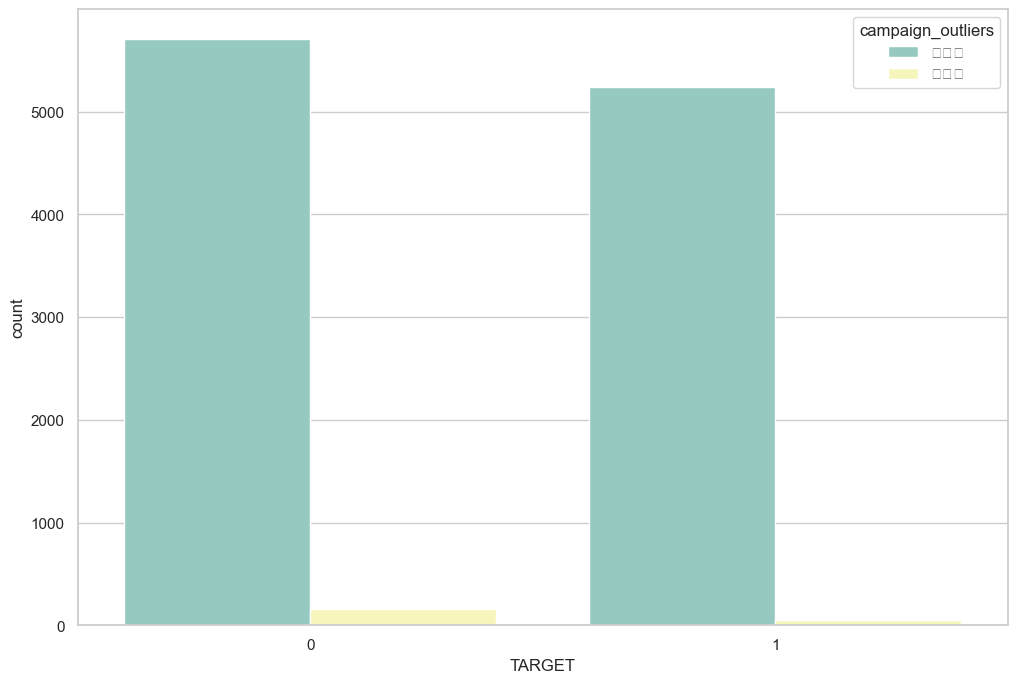

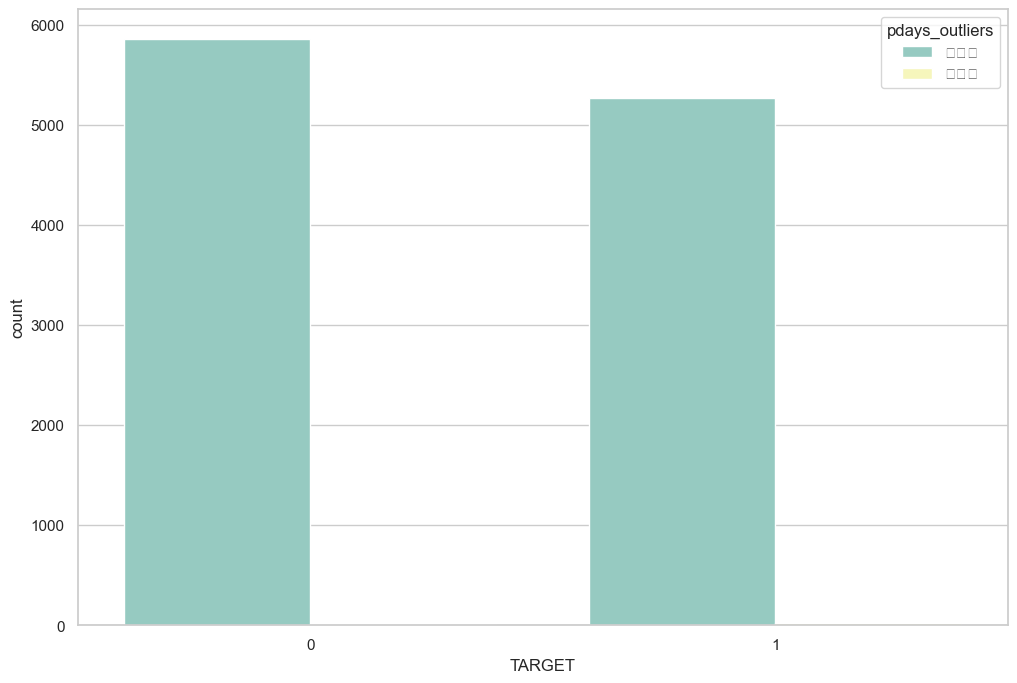

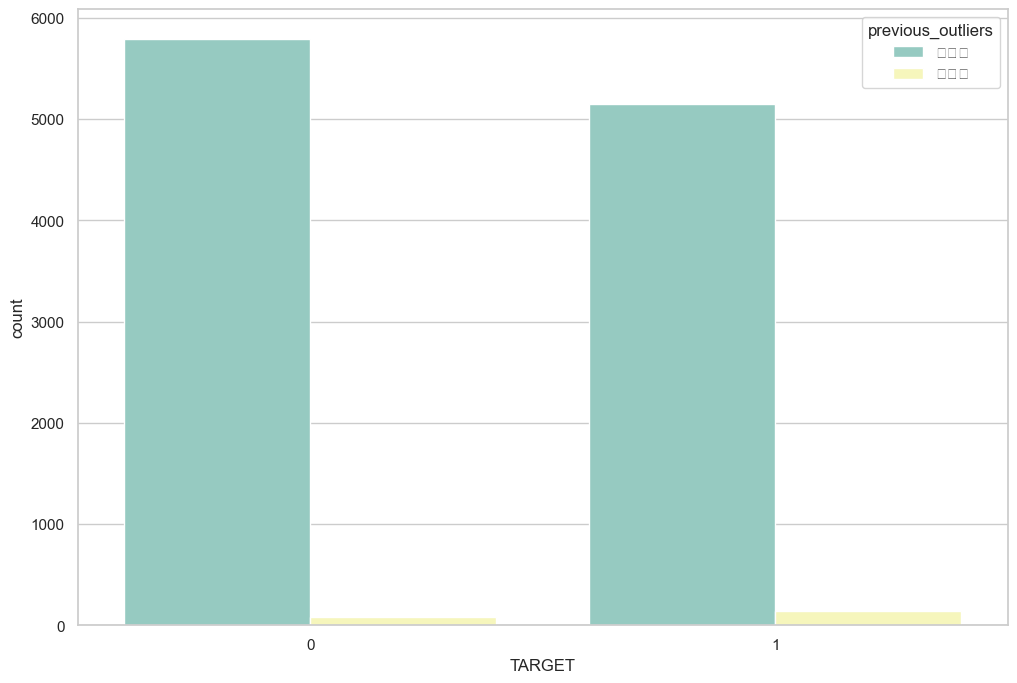

In [36]:
# 模式1：用sns画图
for i in df.select_dtypes('object').columns:
    plt.figure(figsize=(12,8))
    sns.set_theme(style='whitegrid')
    sns.countplot(x=df.TARGET, hue=df[i], palette='Set3')

变量 job 的取值分布，以及target = 1 的占比情况：


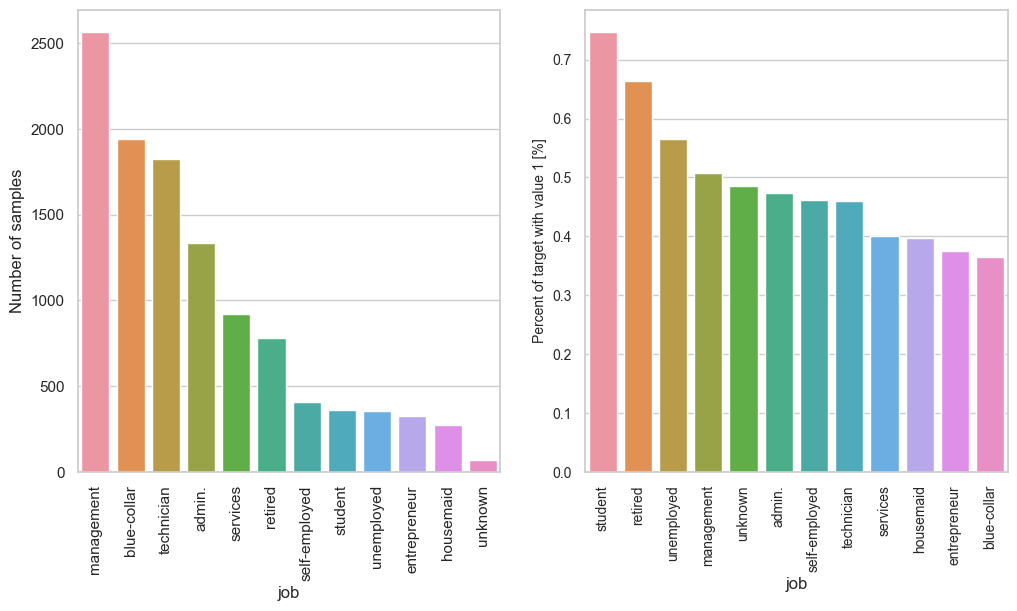

---------------------------------------------------
变量 marital 的取值分布，以及target = 1 的占比情况：


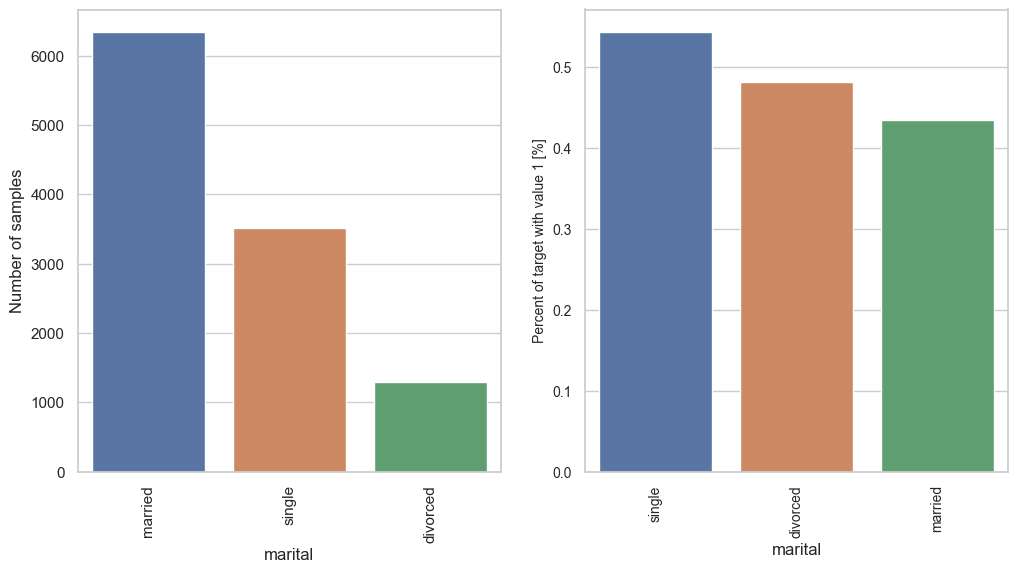

---------------------------------------------------
变量 education 的取值分布，以及target = 1 的占比情况：


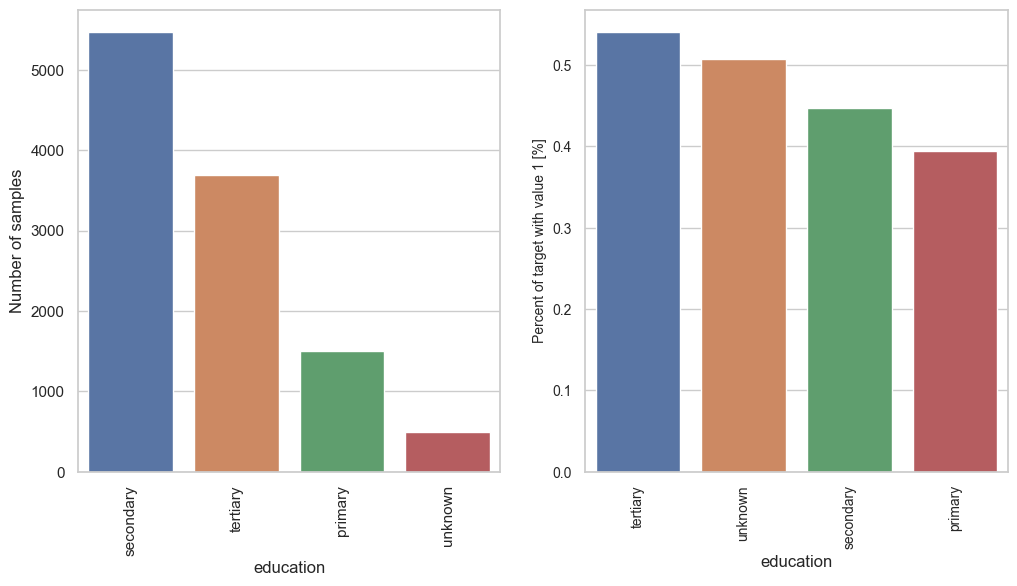

---------------------------------------------------
变量 default 的取值分布，以及target = 1 的占比情况：


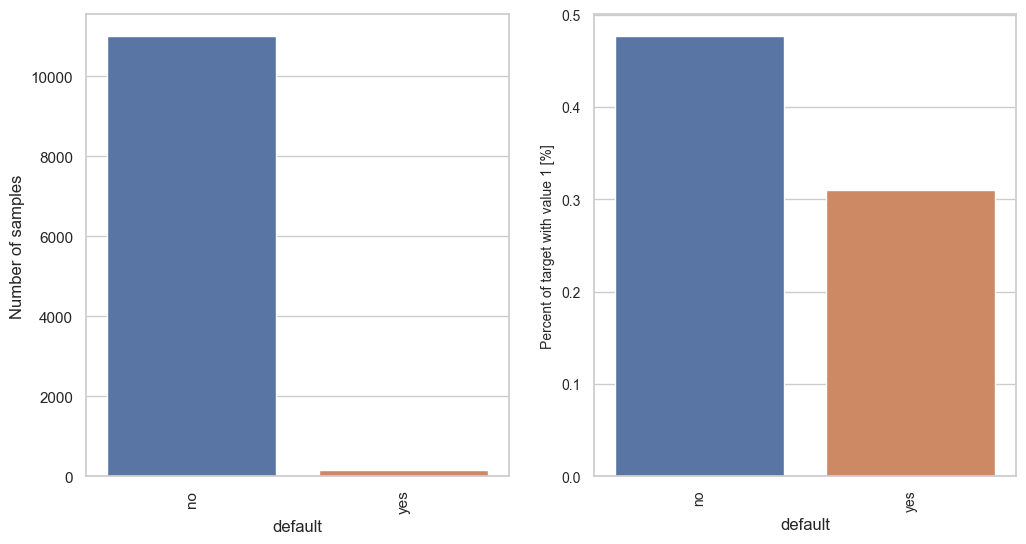

---------------------------------------------------
变量 housing 的取值分布，以及target = 1 的占比情况：


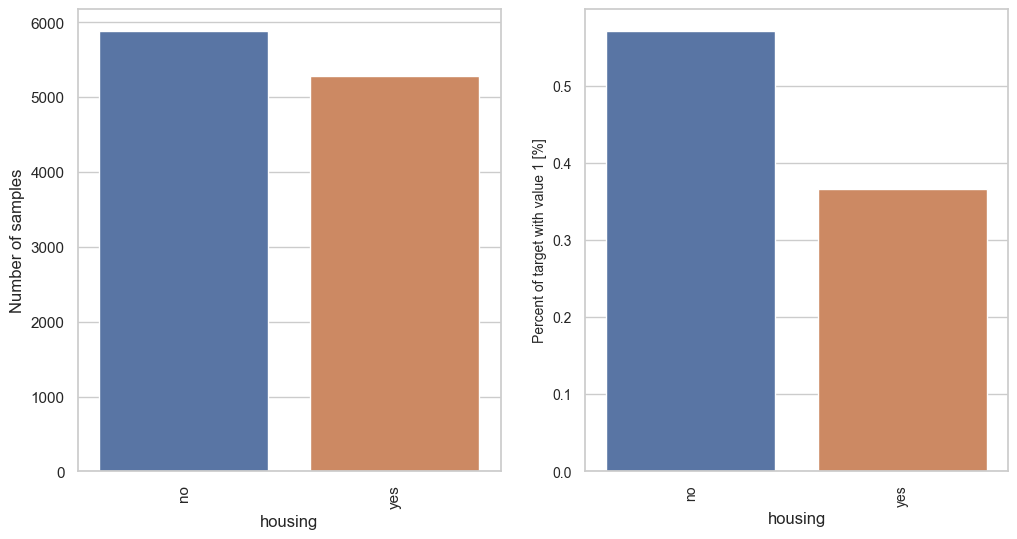

---------------------------------------------------
变量 loan 的取值分布，以及target = 1 的占比情况：


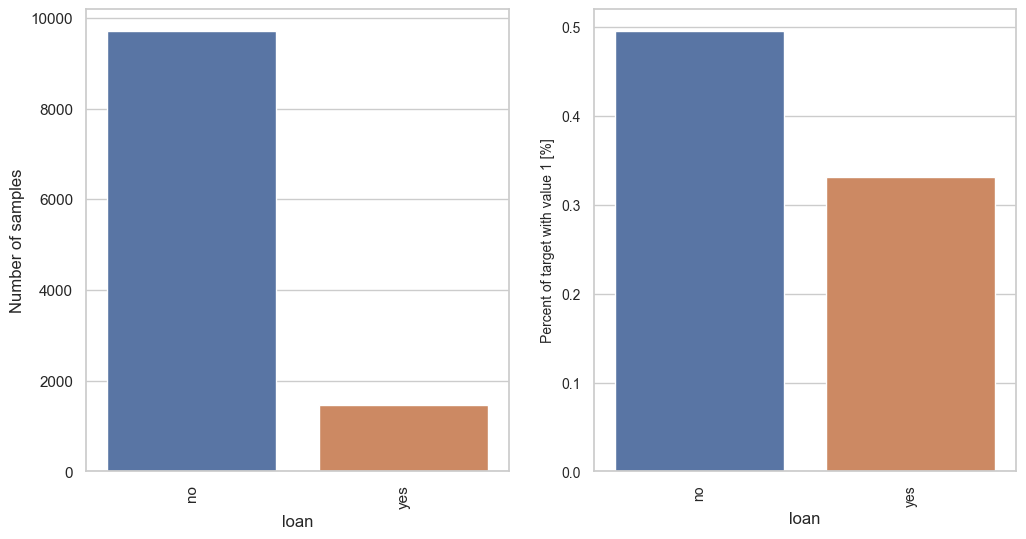

---------------------------------------------------
变量 contact 的取值分布，以及target = 1 的占比情况：


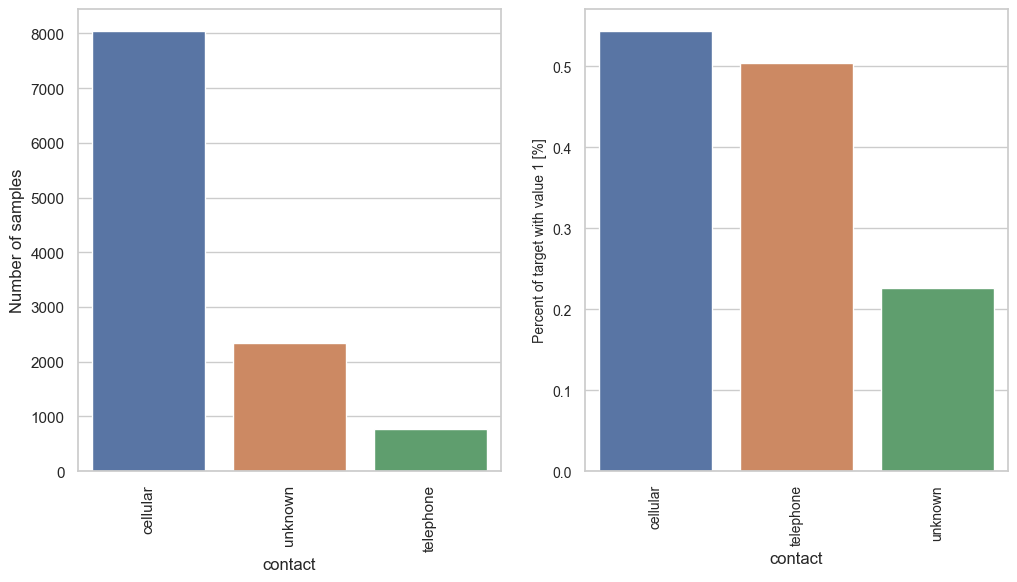

---------------------------------------------------
变量 month 的取值分布，以及target = 1 的占比情况：


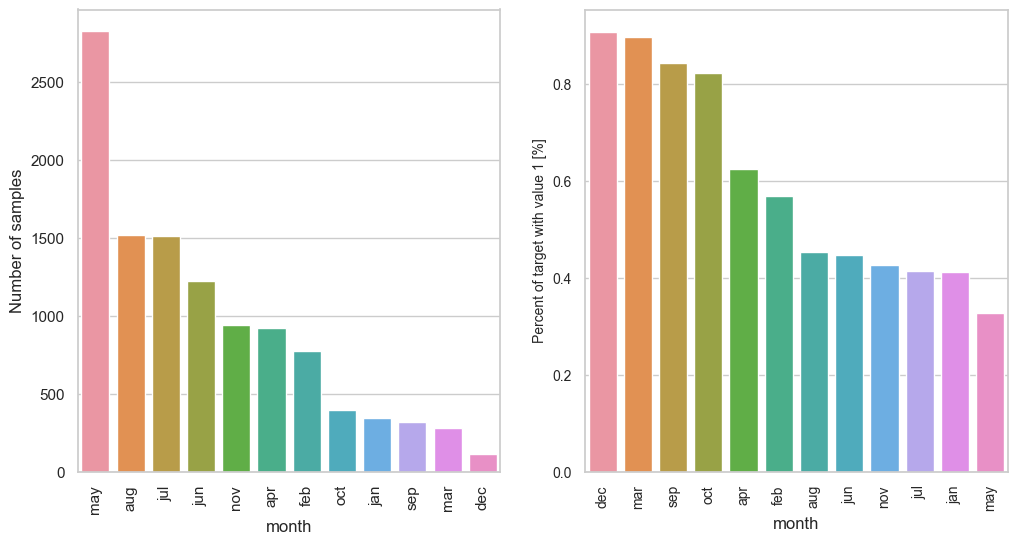

---------------------------------------------------
变量 poutcome 的取值分布，以及target = 1 的占比情况：


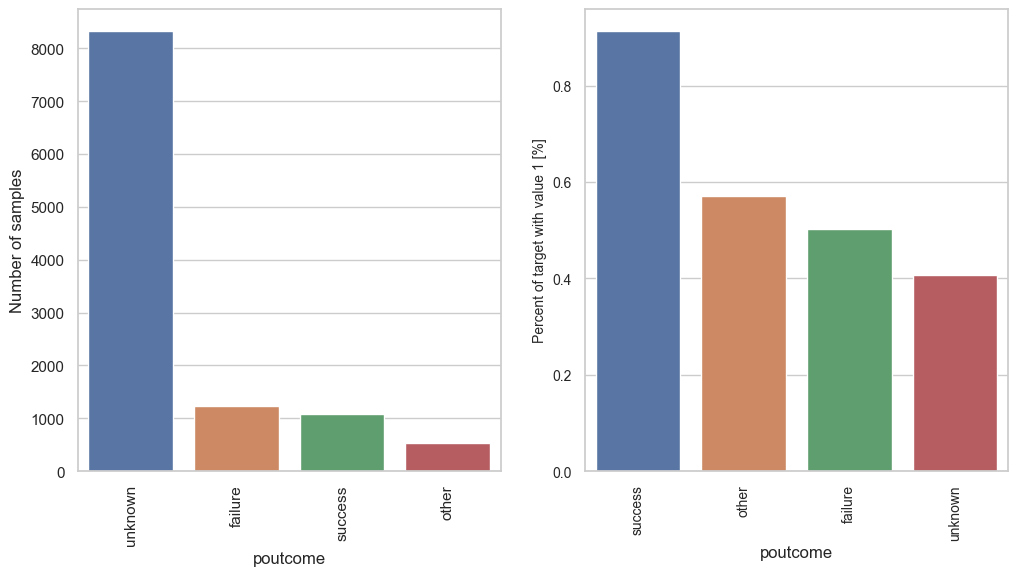

---------------------------------------------------
变量 age_outliers 的取值分布，以及target = 1 的占比情况：


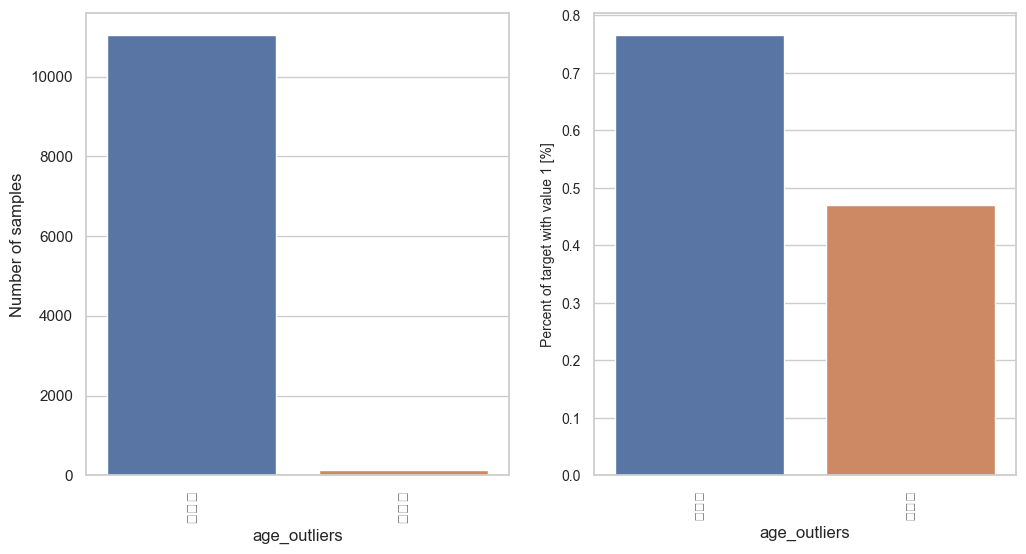

---------------------------------------------------
变量 balance_outliers 的取值分布，以及target = 1 的占比情况：


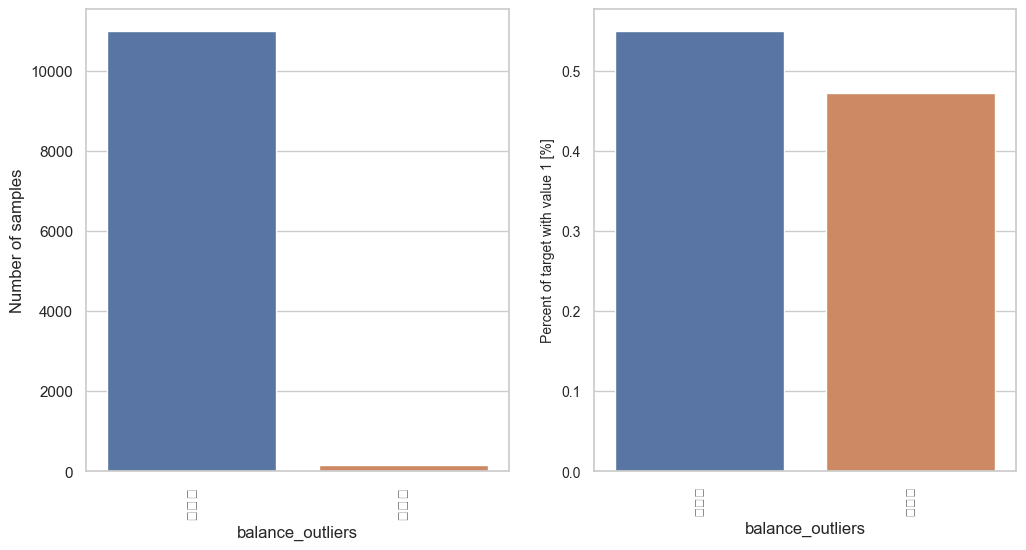

---------------------------------------------------
变量 day_outliers 的取值分布，以及target = 1 的占比情况：


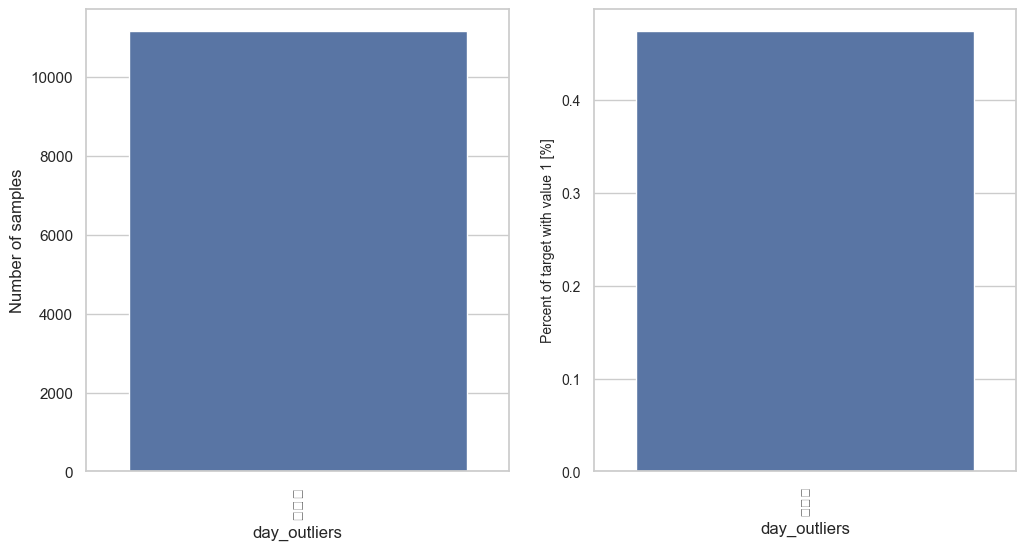

---------------------------------------------------
变量 duration_outliers 的取值分布，以及target = 1 的占比情况：


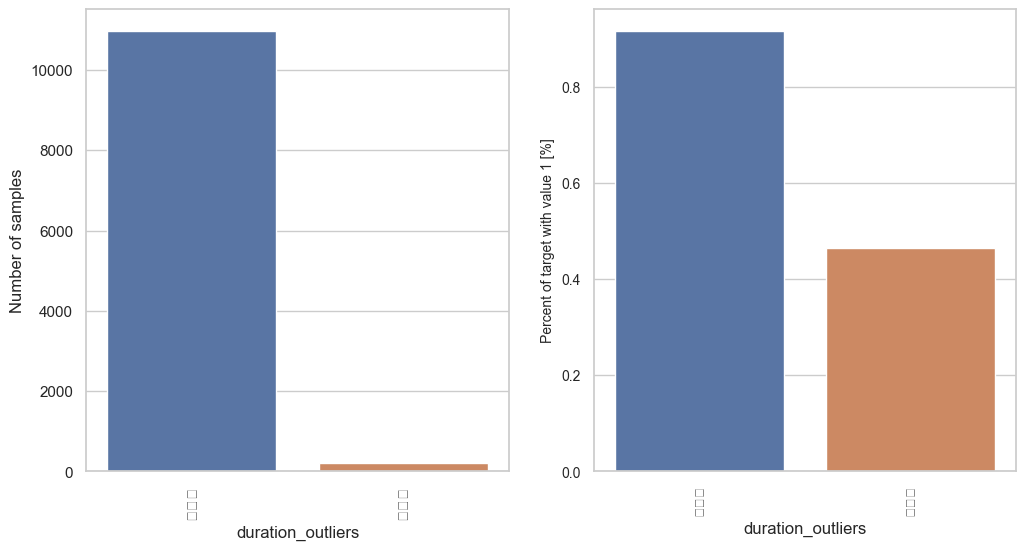

---------------------------------------------------
变量 campaign_outliers 的取值分布，以及target = 1 的占比情况：


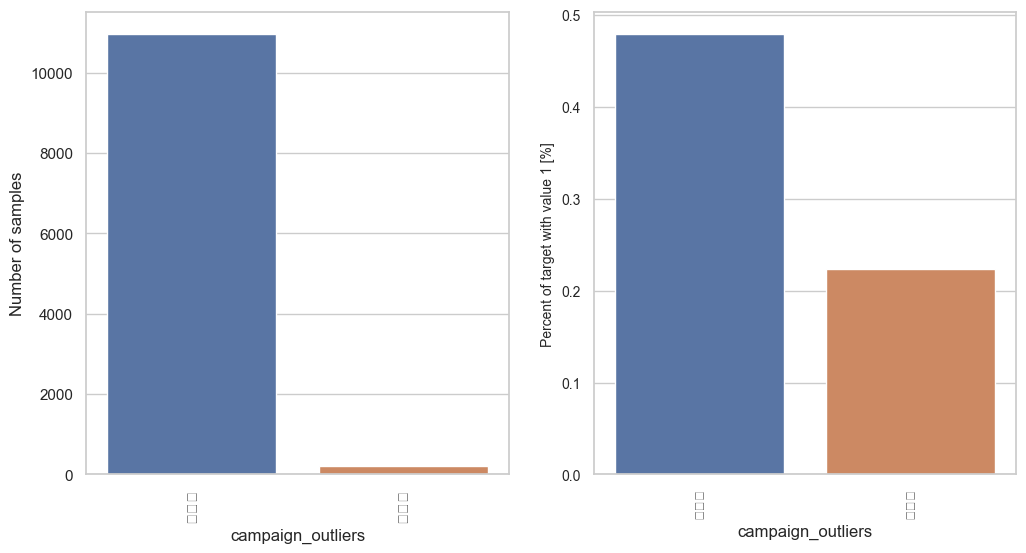

---------------------------------------------------
变量 pdays_outliers 的取值分布，以及target = 1 的占比情况：


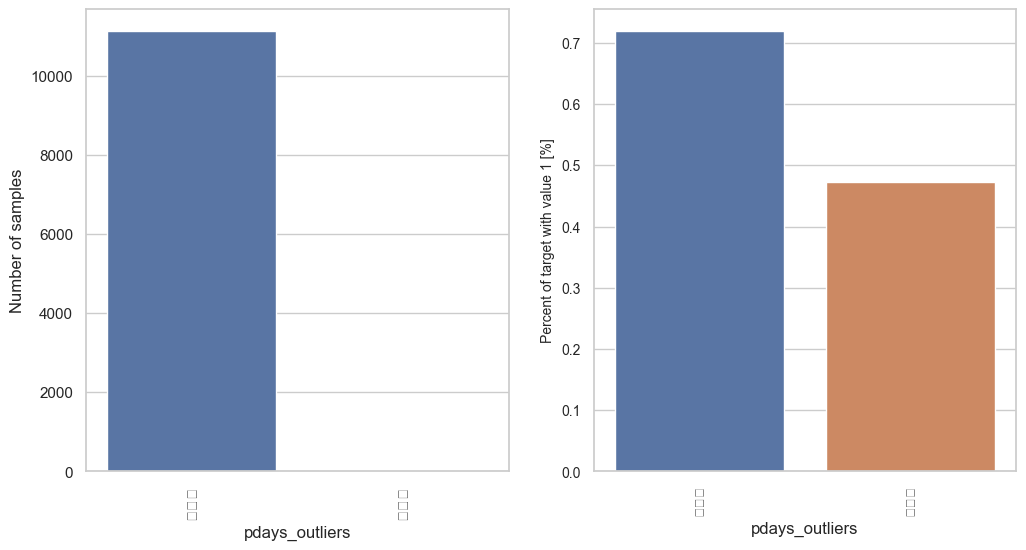

---------------------------------------------------
变量 previous_outliers 的取值分布，以及target = 1 的占比情况：


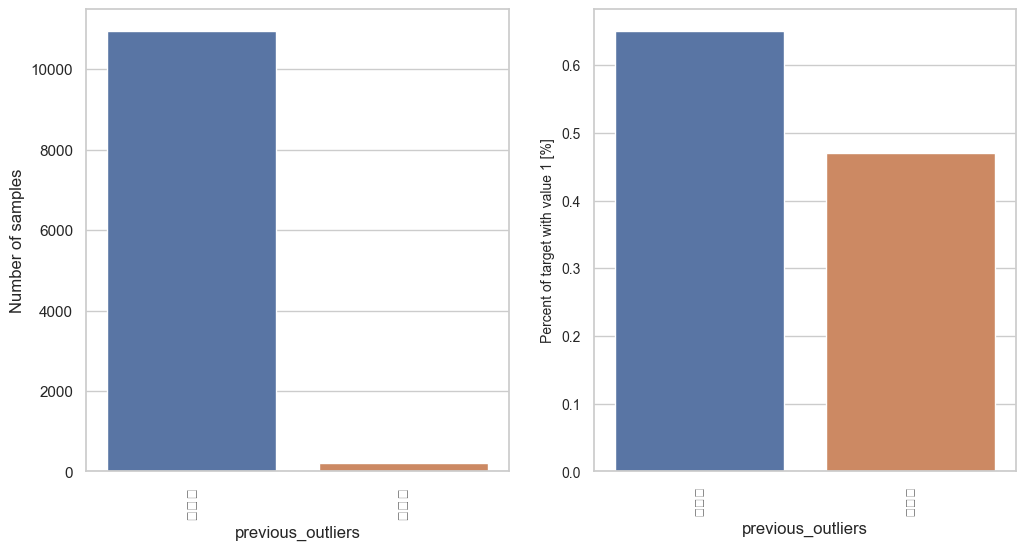

---------------------------------------------------


In [37]:
# 模式2：用定义的函数plot_stats画图
for i in df.select_dtypes('object').columns:
    print(f'变量 {i} 的取值分布，以及target = 1 的占比情况：')
    plot_stats(i,True, True)
    print('---------------------------------------------------')

#### 连续变量VS 目标变量

In [38]:
def plot_distribution_comp(feature):
    plt.figure(figsize = (10, 8))
    
    t1 = df.loc[df['TARGET'] != 0]
    t0 = df.loc[df['TARGET'] == 0]

    sns.kdeplot(t1[feature], bw=0.5,label="TARGET = 1")
    sns.kdeplot(t0[feature], bw=0.5,label="TARGET = 0")
    
    plt.ylabel('Density plot', fontsize=12)
    plt.xlabel(feature, fontsize=12)
    
    locs, labels = plt.xticks()
    plt.tick_params(axis='both', which='major', labelsize=12)
    plt.show()

In [39]:
var = df.select_dtypes(['int64','float']).columns.tolist()
var.remove('TARGET')

变量 age 在target = 1和0情况下的分布情况：


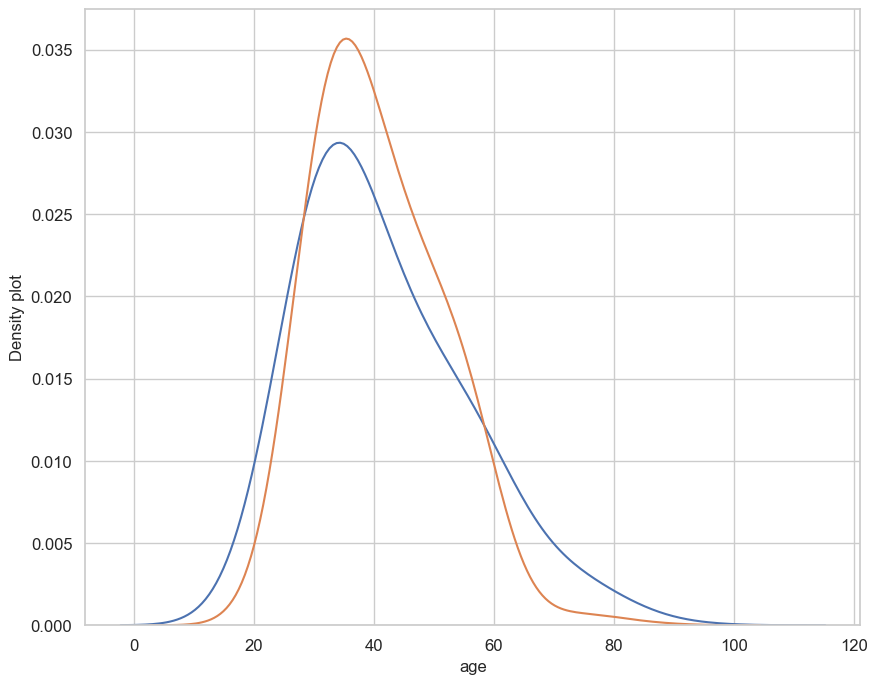

-----------------------------———————————————————————————————————————---
变量 balance 在target = 1和0情况下的分布情况：


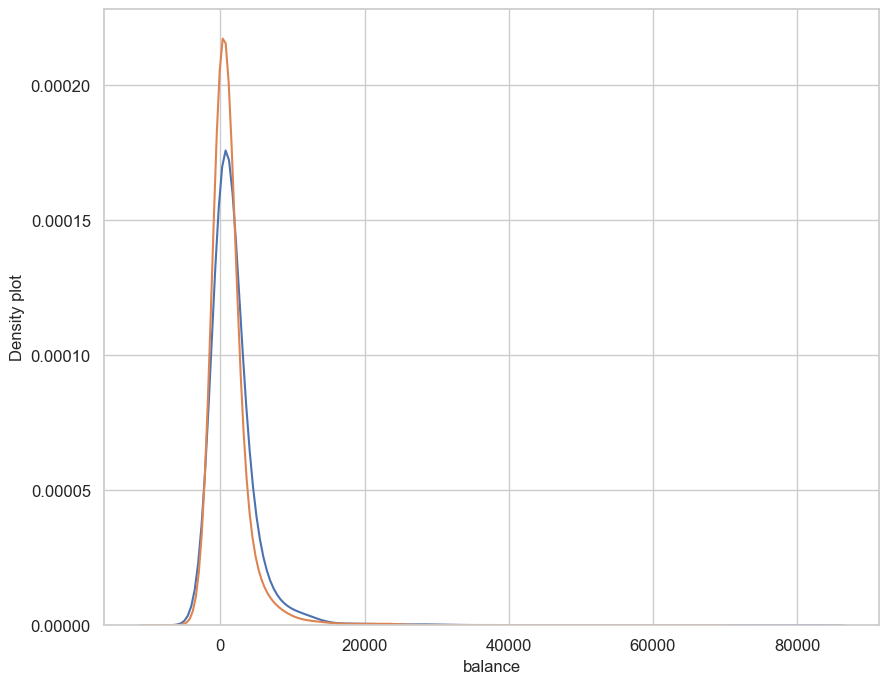

-----------------------------———————————————————————————————————————---
变量 day 在target = 1和0情况下的分布情况：


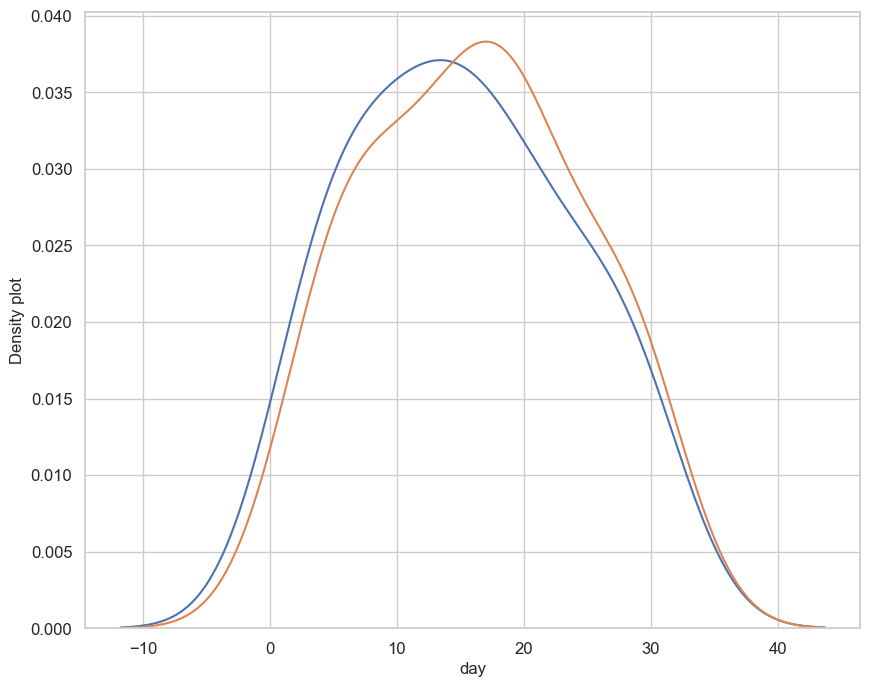

-----------------------------———————————————————————————————————————---
变量 duration 在target = 1和0情况下的分布情况：


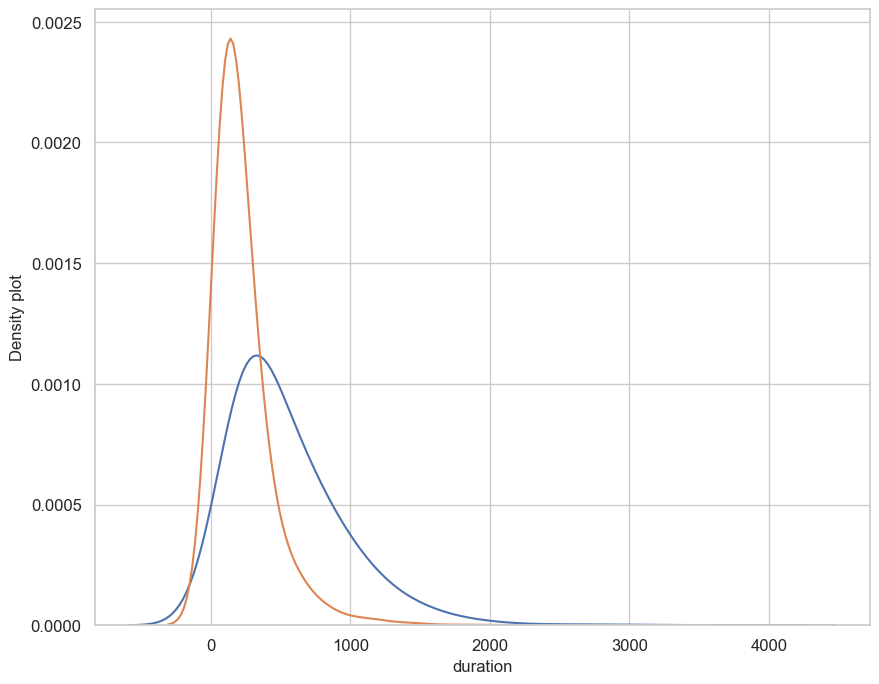

-----------------------------———————————————————————————————————————---
变量 campaign 在target = 1和0情况下的分布情况：


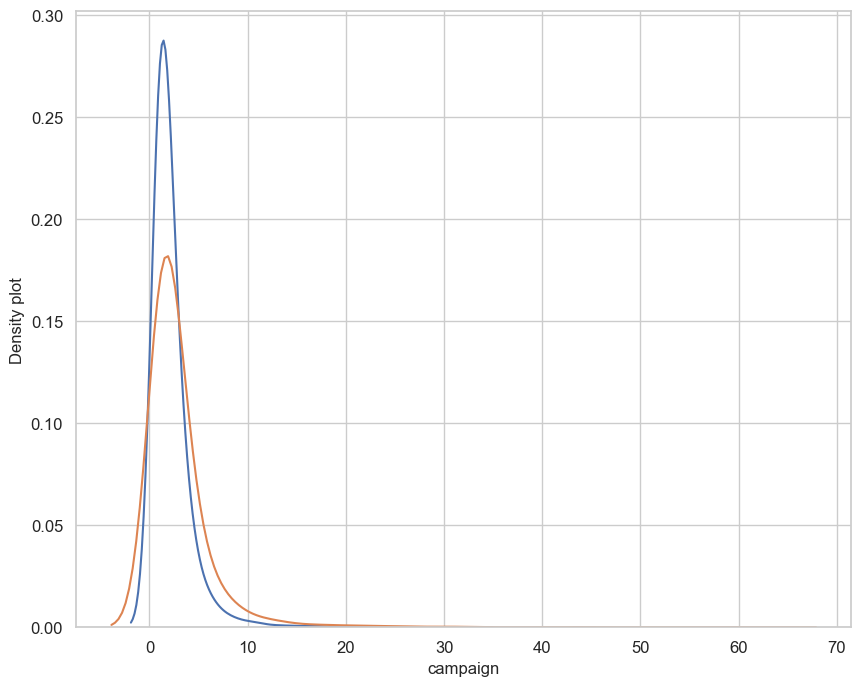

-----------------------------———————————————————————————————————————---
变量 pdays 在target = 1和0情况下的分布情况：


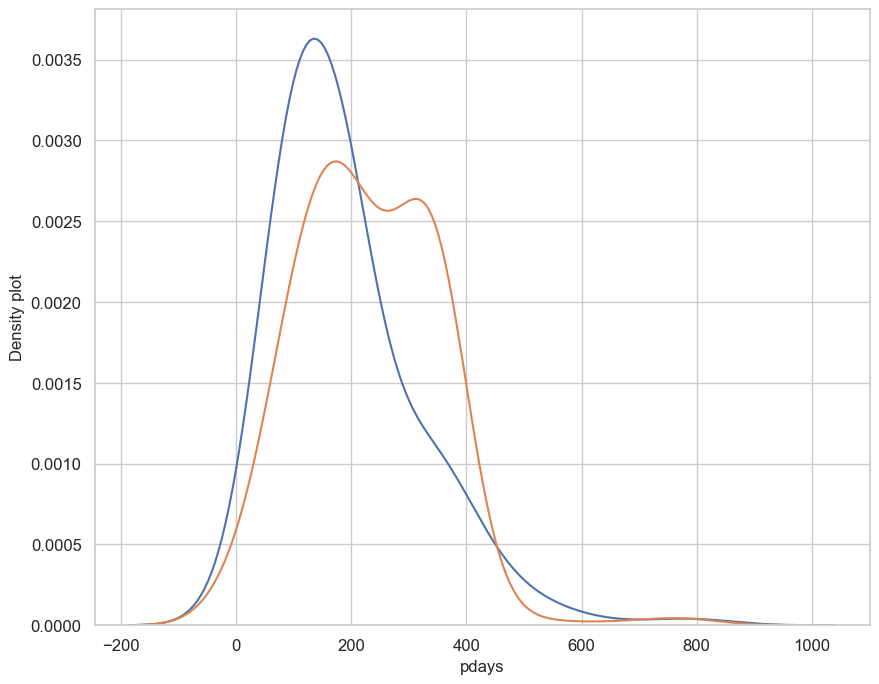

-----------------------------———————————————————————————————————————---
变量 previous 在target = 1和0情况下的分布情况：


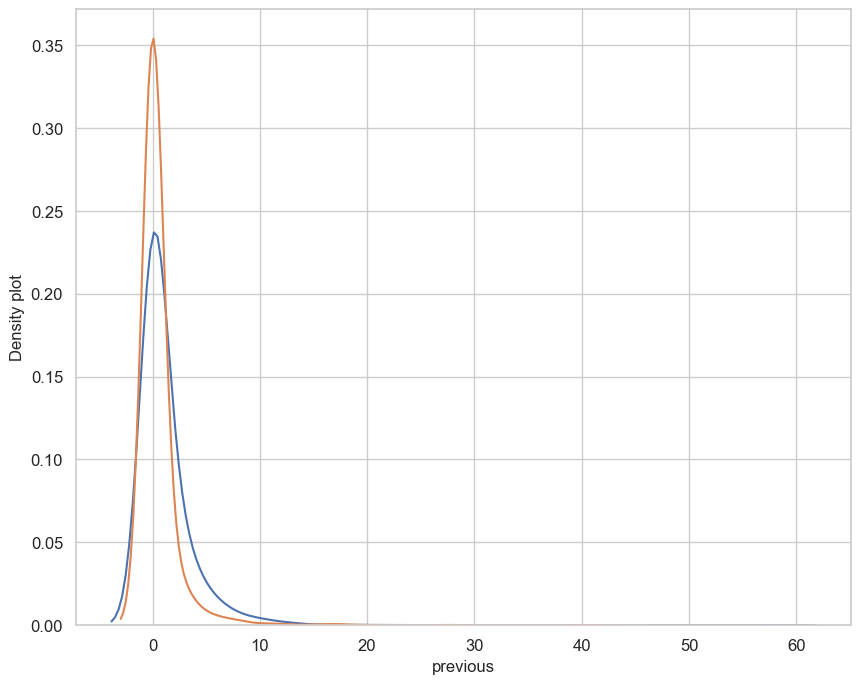

-----------------------------———————————————————————————————————————---


In [40]:
for i in var:
    print(f'变量 {i} 在target = 1和0情况下的分布情况：')
    plot_distribution_comp(feature = i)
    print('-----------------------------———————————————————————————————————————---')

In [41]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,...,poutcome,TARGET,pdays_ANOM,age_outliers,balance_outliers,day_outliers,duration_outliers,campaign_outliers,pdays_outliers,previous_outliers
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,...,unknown,1,True,正常值,正常值,正常值,正常值,正常值,正常值,正常值
1,56,admin.,married,secondary,no,45,no,no,unknown,5,...,unknown,1,True,正常值,正常值,正常值,异常值,正常值,正常值,正常值
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,...,unknown,1,True,正常值,正常值,正常值,正常值,正常值,正常值,正常值
3,55,services,married,secondary,no,2476,yes,no,unknown,5,...,unknown,1,True,正常值,正常值,正常值,正常值,正常值,正常值,正常值
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,...,unknown,1,True,正常值,正常值,正常值,正常值,正常值,正常值,正常值


## 透视表

In [42]:
# 掌握透视图可以让我们更好的了解数据
#透视图 索引可以有多个，“columns（列）”是可选的，聚合函数aggfunc最后是被应用到了变量“values”中你所列举的项目上。
pivot = pd.pivot_table(df, index=['TARGET'], columns=['job'], values=['balance'], aggfunc=np.sum)
pivot

balance                                                         \
job     admin. blue-collar entrepreneur housemaid management  retired   
TARGET                                                                  
0       688360     1437435       308263    178838    1817480   492257   
1       906926      902998       223734    195490    2785061  1388364   

                                                                     
job    self-employed services student technician unemployed unknown  
TARGET                                                               
0             315688   587466  139811    1293077     199835   60264  
1             439788   410455  400471    1544048     269520   75918

# 特征工程

## 变量衍生

### 特征衍生


In [43]:
df.head().T

,0,1,2,3,4
age,59,56,41,55,54
job,admin.,admin.,technician,services,admin.
marital,married,married,married,married,married
education,secondary,secondary,secondary,secondary,tertiary
default,no,no,no,no,no
balance,2343,45,1270,2476,184
housing,yes,no,yes,yes,no
loan,no,no,no,no,no
contact,unknown,unknown,unknown,unknown,unknown
day,5,5,5,5,5


In [44]:

# 转换月和天为日期
df['date'] = pd.to_datetime(df['day'].astype(str) + '-' + df['month'] + '-2020', format='%d-%b-%Y')

# 为重复的日期添加不同的时间戳
df['timestamp'] = df.groupby('date').cumcount()
df['date'] = df.apply(lambda x: x['date'] + pd.DateOffset(seconds=x['timestamp']), axis=1)

# 将日期设置为索引
df.set_index('date', inplace=True)
df.sort_index(inplace=True)  # 排序索引
df['contact_num'] = 1
# 使用 groupby 和 rolling 计算滚动窗口特征
df['contact_last_3_months'] = df.groupby('contact')['contact_num'].rolling(window='90D').sum().shift(1).fillna(0).reset_index(level=0, drop=True)
df['contact_last_6_months'] = df.groupby('contact')['contact_num'].rolling(window='180D').sum().shift(1).fillna(0).reset_index(level=0, drop=True)
df['contact_last_12_months'] = df.groupby('contact')['contact_num'].rolling(window='365D').sum().shift(1).fillna(0).reset_index(level=0, drop=True)

df.reset_index(inplace=True)
# 其他特征衍生
# 最近一次联系的月份数
df['month_num'] = df['date'].dt.month

# 账户余额的统计特征
df['balance_mean'] = df['balance'].mean()
df['balance_median'] = df['balance'].median()
df['balance_std'] = df['balance'].std()

# 联系次数的统计特征
df['campaign_mean'] = df['campaign'].mean()
df['campaign_std'] = df['campaign'].std()

# 是否有任何贷款
df['has_any_loan'] = df.apply(lambda x: 'yes' if x['housing'] == 'yes' or x['loan'] == 'yes' else 'no', axis=1)

# 上次活动的成功率
df['previous_success_rate'] = df['poutcome'].apply(lambda x: 1 if x == 'success' else 0).cumsum() / (df.index + 1)
df.drop(columns=['timestamp', 'date'], inplace=True)

df.head()


                 date  age         job  marital  education default  balance  \
0 2020-01-07 00:00:00   45  unemployed  married  secondary      no      891   
1 2020-01-08 00:00:00   70     retired  married    primary      no     2795   
2 2020-01-08 00:00:01   27  management   single  secondary      no      843   
3 2020-01-11 00:00:00   25  technician   single  secondary      no      139   
4 2020-01-11 00:00:01   57     retired  married  secondary      no     1044   

  housing loan    contact  ...  contact_last_6_months contact_last_12_months  \
0     yes   no    unknown  ...                  445.0                  774.0   
1      no   no   cellular  ...                    0.0                    0.0   
2      no   no   cellular  ...                    1.0                    1.0   
3      no  yes   cellular  ...                    2.0                    2.0   
4      no   no  telephone  ...                 4219.0                 8042.0   

   month_num  balance_mean  balance_median  

### 根据特征交互衍生

* 尝试变量之间的加减乘除组合
* 尝试变量的统计特征

In [56]:
# 连续性变量、分类变量各有多少
 
# 数值型特征
numerical_fea = list(df.select_dtypes(exclude=['object']).columns)
# 分类型特征
category_fea = list(filter(lambda x: x not in numerical_fea,list(df.columns)))
#category_fea = list(data_train.select_dtypes(include = ['object']).columns)

## 变量处理

### 缺失值填充
缺失值性质
* 这个值实际存在，但是没有被观测到。例如客户消费金额本应该是1万，但实际为空。
* 这个值实际不存在，例如，顾客没有进行任何消费，那么消费金额这一变量必然缺失。

* 连续型
 * 根据业务定义优先确定空值是否能用0填充
 * 分箱
 * 接近正态分布，用均值填充
 * 数据偏度较大，用中位数填充
 
* 离散变量
 * 根据业务定义优先确定空值是否能用0填充
 * 设定为未知
 * 无法确定用众数填充

#### 直接填充
* 单变量填补  
用单一变量的均值/中位数/众数/二分之一最小值/零值进行补值。  
这种方法会导致数据分布的偏移，方差偏小，PCA上会看到一条补值导致的直线等问题。
这种方法仅在缺失数据集满足正态分布的情况下可以达到比较好的效果,而在现实应用中,往往连对数据具一定的先验知识都很难做到,而现实数据往往又并不是简单的正态分布,因此这一方法不可避免的将带来数据的各种统计参数的扭曲

In [57]:
#按照平均数填充数值型特征
df[numerical_fea] = df[numerical_fea].fillna(df[numerical_fea].median())
#按照众数填充类别型特征
df[category_fea] = df[category_fea].fillna(df[category_fea].mode())


#### 插值填充
所谓的插值法就是通过两点（x0，y0），（x1，y1）估计中间点的值，假设y=f(x)是一条直线，通过已知的两点来计算函数f(x),然后只要知道x就能求出y，以此方法来估计缺失值。当然我们也可以假设f（x)不是直线，而是其他函数。

interpolate函数默认采用线性插值，即假设函数是直线形式，缺失值用前一个值和后一个值的平均数填充。
还可以根据数字来进行插值，用到参数method=‘values’，此时索引的数值实际上就是用于估计y的x值。
如果index是时间，我们还可以用method=time来插值。不过当dataframe是多重索引(multiIndex)时，只能用线性插值。
此外还可以通过参数设定采用多项式插值填充等方式。 

In [58]:
# data = pd.read_csv(path,encoding='gbk')
# for f in data:  # 插值法填充
#     data[f] = data[f].interpolate()
#     data.dropna(inplace=True)

### 异常值处理

In [59]:
# TODO

### 类别变量处理 

* Label encoding: 将每个类别转化成一个对应的整数 
* One-hot encoding: 将每个类别转化成一个新的变量，用0,1表示其取值。 独热编码。 

* 评价：
 - label encoding 转化成整数后，赋予了主观顺序。 
 - one-hot encoding 相对来说是一种比较安全的编码。但缺点是当变量取值过多，会导致特征个数急剧增加，可用[PCA](http://www.cs.otago.ac.nz/cosc453/student_tutorials/principal_components.pdf) or other [dimensionality reduction methods](https://www.analyticsvidhya.com/blog/2015/07/dimension-reduction-methods/) 来降维。 

In [60]:
########## label encoding 代码示例##############

# 创建一个label encoder 对象 
le = LabelEncoder()
le_count = 0

# 对数据中的每一列：
for col in df:
    if df[col].dtype == 'object': # 如果本列是类别变量

        if len(list(df[col].unique())) <= 2: # 如果unique取值个数不大于2：

            le.fit(df[col]) # 用LabelEncoder转换变量
   
            df[col] = le.transform(df[col]) #应用到数据上
 
            # 记录有多少列被转换 
            le_count += 1
            
print('%d columns were label encoded.' % le_count)

0 columns were label encoded.


In [61]:
########  one-hot encoding 代码示例 ############## 
df = pd.get_dummies(df) 

In [62]:
df.head()

,age,default,balance,housing,loan,day,duration,campaign,pdays,previous,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
0,45,0,891,1,0,7,118,1,182.0,0,...,False,False,False,False,False,False,False,False,False,True
1,70,0,2795,0,0,8,301,2,182.0,0,...,False,False,False,False,False,False,False,False,False,True
2,27,0,843,0,0,8,187,1,182.0,0,...,False,False,False,False,False,False,False,False,False,True
3,25,0,139,0,1,11,202,1,91.0,1,...,False,False,False,False,False,False,False,False,True,False
4,57,0,1044,0,0,11,585,1,192.0,2,...,False,False,False,False,False,False,False,False,True,False


In [63]:
print('转换后的数据信息：', df.shape) 

转换后的数据信息： (11162, 69)


### 连续变量处理

####  正态化转换

* 查看某一个数值型变量的分布是否符合正态分布，如果不符合正太分布的变量可以log化后再观察下是否符合正态分布。

* 正态化的原因：在某些情况下正态非正态可以让模型更快收敛，有些模型要求数据正态（eg. GMM、KNN）,保证数据不要过偏态即可，过于偏态可能会影响模型预测结果

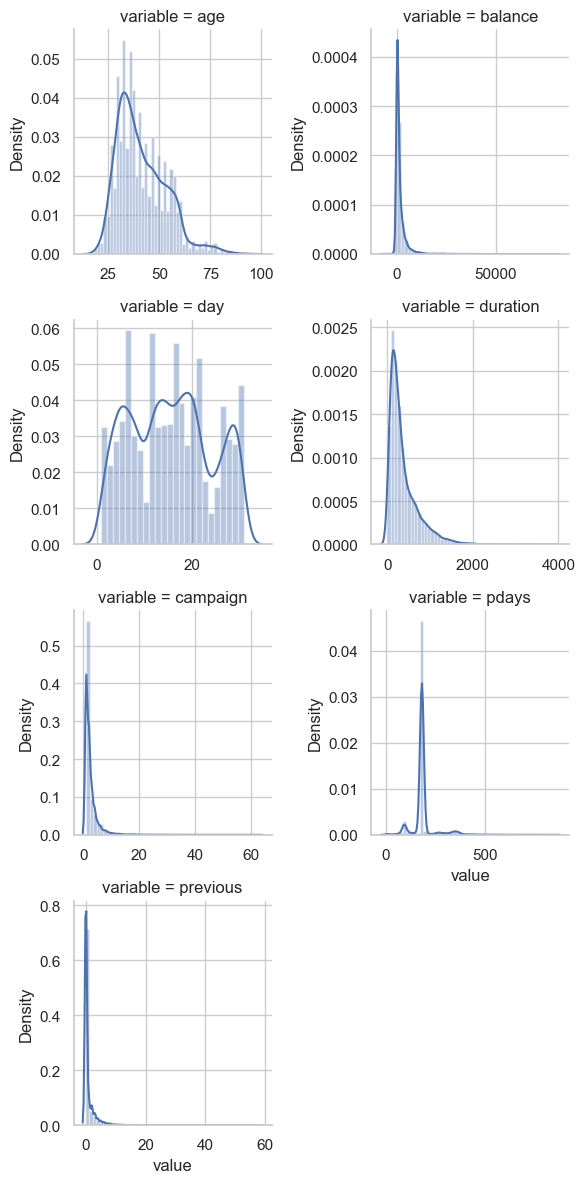

In [64]:
# 连续型数值变量的分析
f = pd.melt(df,value_vars=numerical_serial_fea)
g = sns.FacetGrid(f,col="variable",col_wrap=2,sharex=False,sharey=False)
g = g.map(sns.distplot,"value")

#### 值的转化

In [67]:
# ################  Age 为例 #####################
# # Find the correlation of the positive days since birth and target
# df['age'] = abs(df['DAYS_BIRTH'])/365 # 取绝对值
# # 看一下age变量的分布 
# plt.hist(df['age'], edgecolor = 'k', bins = 25)

## 变量分箱

数据分箱的重要性及优势：

- 离散特征的增加和减少都很容易，易于模型的快速迭代；
- 稀疏向量内积乘法运算速度快，计算结果方便存储，容易扩展；
- 离散化后的特征对异常数据有很强的鲁棒性：比如一个特征是年龄>30是1，否则0。如果特征没有离散化，一个异常数据“年龄300岁”会给模型造成很大的干扰；

- 逻辑回归属于广义线性模型，表达能力受限；单变量离散化为N个后，每个变量有单独的权重，相当于为模型引入了非线性，能够提升模型表达能力，加大拟合；
- 离散化后可以进行特征交叉，由M+N个变量变为M*N个变量，进一步引入非线性，提升表达能力；
- 特征离散化后，模型会更稳定，比如如果对用户年龄离散化，20-30作为一个区间，不会因为一个用户年龄长了一岁就变成一个完全不同的人。当然处于区间相邻处的样本会刚好相反，所以怎么划分区间是门学问；
- 特征离散化以后，起到了简化了逻辑回归模型的作用，降低了模型过拟合的风险。
- 可以将缺失作为独立的一类带入模型。
- 将所有变量变换到相似的尺度上。

### 等频分箱

In [68]:
######## 等频示例 ###############
def bin_frequency(x,y,n=10): # x为待分箱的变量，y为target变量.n为分箱数量
    total = y.count()  # 计算总样本数
    bad = y.sum()      # 计算坏样本数
    good = y.count()-y.sum()  # 计算好样本数
    d1 = pd.DataFrame({'x':x,'y':y,'bucket':pd.qcut(x,n)})  # 用pd.cut实现等频分箱
    d2 = d1.groupby('bucket',as_index=True)  # 按照分箱结果进行分组聚合
    d3 = pd.DataFrame(d2.x.min(),columns=['min_bin']) 
    d3['min_bin'] = d2.x.min()  # 箱体的左边界
    d3['max_bin'] = d2.x.max()  # 箱体的右边界
    d3['bad'] = d2.y.sum()  # 每个箱体中坏样本的数量
    d3['total'] = d2.y.count() # 每个箱体的总样本数
    d3['bad_rate'] = d3['bad']/d3['total']  # 每个箱体中坏样本所占总样本数的比例
    d3['badattr'] = d3['bad']/bad   # 每个箱体中坏样本所占坏样本总数的比例
    d3['goodattr'] = (d3['total'] - d3['bad'])/good  # 每个箱体中好样本所占好样本总数的比例
    d3['woe'] = np.log(d3['goodattr']/d3['badattr'])  # 计算每个箱体的woe值
    iv = ((d3['goodattr']-d3['badattr'])*d3['woe']).sum()  # 计算变量的iv值
    d4 = (d3.sort_values(by='min_bin')).reset_index(drop=True) # 对箱体从大到小进行排序
    print('分箱结果：')
    print(d4)
    print('IV值为：')
    print(iv)
    cut = []
    cut.append(float('-inf'))
    for i in d4.min_bin:
        cut.append(i)
    cut.append(float('inf'))
    woe = list(d4['woe'].round(3))
    return d4,iv,cut,woe

### 等距分箱

In [69]:
############# 等距示例 ###################
def bin_distince(x,y,n=10): # x为待分箱的变量，y为target变量.n为分箱数量
    total = y.count()  # 计算总样本数
    bad = y.sum()      # 计算坏样本数
    good = y.count()-y.sum()  # 计算好样本数
    d1 = pd.DataFrame({'x':x,'y':y,'bucket':pd.cut(x,n)}) #利用pd.cut实现等距分箱
    d2 = d1.groupby('bucket',as_index=True)  # 按照分箱结果进行分组聚合
    d3 = pd.DataFrame(d2.x.min(),columns=['min_bin']) 
    d3['min_bin'] = d2.x.min()  # 箱体的左边界
    d3['max_bin'] = d2.x.max()  # 箱体的右边界
    d3['bad'] = d2.y.sum()  # 每个箱体中坏样本的数量
    d3['total'] = d2.y.count() # 每个箱体的总样本数
    d3['bad_rate'] = d3['bad']/d3['total']  # 每个箱体中坏样本所占总样本数的比例
    d3['badattr'] = d3['bad']/bad   # 每个箱体中坏样本所占坏样本总数的比例
    d3['goodattr'] = (d3['total'] - d3['bad'])/good  # 每个箱体中好样本所占好样本总数的比例
    d3['woe'] = np.log(d3['goodattr']/d3['badattr'])  # 计算每个箱体的woe值
    iv = ((d3['goodattr']-d3['badattr'])*d3['woe']).sum()  # 计算变量的iv值
    d4 = (d3.sort_values(by='min_bin')).reset_index(drop=True) # 对箱体从大到小进行排序
    print('分箱结果：')
    print(d4)
    print('IV值为：')
    print(iv)
    cut = []
    cut.append(float('-inf'))
    for i in d4.min_bin:
        cut.append(i)
    cut.append(float('inf'))
    woe = list(d4['woe'].round(3))
    return d4,iv,cut,woe

### 自定义分箱

In [70]:
#################自定义示例 ####################
def bin_self(x,y,cut): # x为待分箱的变量，y为target变量,cut为自定义的分箱(list)
    total = y.count()  # 计算总样本数
    bad = y.sum()      # 计算坏样本数
    good = y.count()-y.sum()  # 计算好样本数
    d1 = pd.DataFrame({'x':x,'y':y,'bucket':pd.cut(x,cut)}) 
    d2 = d1.groupby('bucket',as_index=True)  # 按照分箱结果进行分组聚合
    d3 = pd.DataFrame(d2.x.min(),columns=['min_bin']) 
    d3['min_bin'] = d2.x.min()  # 箱体的左边界
    d3['max_bin'] = d2.x.max()  # 箱体的右边界
    d3['bad'] = d2.y.sum()  # 每个箱体中坏样本的数量
    d3['total'] = d2.y.count() # 每个箱体的总样本数
    d3['bad_rate'] = d3['bad']/d3['total']  # 每个箱体中坏样本所占总样本数的比例
    d3['badattr'] = d3['bad']/bad   # 每个箱体中坏样本所占坏样本总数的比例
    d3['goodattr'] = (d3['total'] - d3['bad'])/good  # 每个箱体中好样本所占好样本总数的比例
    d3['woe'] = np.log(d3['goodattr']/d3['badattr'])  # 计算每个箱体的woe值
    iv = ((d3['goodattr']-d3['badattr'])*d3['woe']).sum()  # 计算变量的iv值
    d4 = (d3.sort_values(by='min_bin')).reset_index(drop=True) # 对箱体从大到小进行排序
    print('分箱结果：')
    print(d4)
    print('IV值为：')
    print(iv)
    woe = list(d4['woe'].round(3))
    return d4,iv,woe

# 建模前数据准备

## 划分数据集

In [71]:
df_x = df.drop(columns = 'TARGET')
df_y = df['TARGET']

In [72]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df_x, df_y, test_size=0.1, random_state=42)

In [73]:
print('Training data shape: ', X_train.shape)
print('Testing data shape: ', X_test.shape)
print(y_train.value_counts())

Training data shape:  (10045, 68)
Testing data shape:  (1117, 68)
TARGET
0    5263
1    4782
Name: count, dtype: int64


In [74]:
########## 注：以下仅为本例示例，不同样本需根据实际情况填充 ###########
from sklearn.impute import SimpleImputer

# Median imputation of missing values
imputer = SimpleImputer(strategy = 'median')

# Fit on the training data
imputer.fit(X_train)

# 转换
X_train_1 = imputer.transform(X_train)
X_test_1 = imputer.transform(X_test)

## 连续变量进行归一化

* 逻辑回归等模型单独增加的特征工程
* 对特征做归一化，目的是让训练过程更好更快的收敛，避免特征大吃小的问题
* 去除相关性是增加模型的可解释性，加快预测过程。

In [75]:
from sklearn.preprocessing import MinMaxScaler

# Scale each feature to 0-1
scaler = MinMaxScaler(feature_range = (0, 1))
scaler.fit(X_train_1)
X_train_2 = scaler.transform(X_train_1) 
X_test_2 = scaler.transform(X_test_1) 

## 样本不均衡的处理方式

1. 扩充数据集  
2. 尝试其他评价指标：AUC等  
3. 调整θ值  
4. 重采样：过采样/欠采样  
5. 合成样本： SMOTE  
6. 选择其他模型：决策树等  
7. 加权少类别的样本错分代价  
8. 将大类分解成多个小类  
注意：重采样只能运用在训练集，不能运用在验证集和测试集。

In [76]:
from imblearn.combine import SMOTETomek
#是否需要过采样
if need_imblearn:
    print('oversample processing....')
    smote_tomek = SMOTETomek(random_state=0)
    X_train_2, y_train = smote_tomek.fit_resample(X_train_2, y_train)

oversample processing....


In [77]:
print('Training data shape: ', X_train.shape)
print('Testing data shape: ', X_test.shape)
print(y_train.value_counts())

Training data shape:  (10045, 68)
Testing data shape:  (1117, 68)
TARGET
1    4571
0    4571
Name: count, dtype: int64


## 进一步将训练集分为（训练集+验证集）

In [78]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(X_train_2, y_train, test_size=0.2, random_state=42)

# 建模与优化

## 逻辑回归

逻辑回归模型对变量的要求：

* 变量间不存在较强的线性相关性和多重共线性；
* 变量具有显著性；
* 变量具有合理的业务含义。

In [79]:
from sklearn import metrics
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [80]:
# 调用逻辑回归模型
LogisticReg = LogisticRegression(C = 0.0001)

# 在训练集上拟合模型
LogisticReg.fit(X_train, y_train)

# 得到测试集上的预测值：
y_pred = LogisticReg.predict_proba(X_test_2)[:, 1]

# 将预测值与真实值比较，得出AUC值
lr_auc = roc_auc_score(y_test, y_pred)

### 网格搜索法调参示例

In [81]:
from sklearn.model_selection import GridSearchCV

# 设定参数可能范围
grid_param = {"tol":[1e-4, 1e-3,1e-2], "C":[0.4, 0.6, 0.8]}
grid_clf = GridSearchCV(LogisticReg,grid_param)

# 调用fit方法执行网格搜索
grid_clf.fit(X_train, y_train)

#使用最好的分类器去求测试数据精度。
LogisticReg = grid_clf.best_estimator_

# 得到测试集上的预测值
y_pred_LogisticReg = LogisticReg.predict_proba(X_test_2)[:, 1]

# 将预测值与真实值比较，得出AUC值
lr_auc_aftersearch = roc_auc_score(y_test, y_pred_LogisticReg)

### 调参结果对照

In [82]:
print(f'调参前模型（基于训练集），验证集AUC：{lr_auc}')
print(f'调参后模型（基于训练集），验证集AUC：{lr_auc_aftersearch}')

调参前模型（基于训练集），验证集AUC：0.7032398874769619
调参后模型（基于训练集），验证集AUC：0.8937853655382029


## 决策树

In [83]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier()
dt = dt.fit(X_train, y_train)

In [84]:
# 得到预测结果
y_pred_dt= dt.predict_proba(X_test_2)[:, 1]
# 评估模型表现
dt_auc = roc_auc_score(y_test, y_pred_dt)

### 调参

In [85]:
# 设定参数可能范围
grid_param = {"max_depth":[6,7,8,9]}
grid_dt = GridSearchCV(dt,grid_param)

# 调用fit方法执行网格搜索
grid_dt.fit(X_train, y_train)

#使用最好的分类器去求测试数据精度。
decision_tree_model = grid_dt.best_estimator_

# 得到测试集上的预测值：
y_pred_dt = decision_tree_model.predict_proba(X_test_2)[:, 1]

# 将预测值与真实值比较，得出AUC值
dt_auc_aftersearch = roc_auc_score(y_test, y_pred_dt)

### 调参结果对照

In [86]:
print(f'调参前模型（基于训练集），验证集AUC：{dt_auc}')
print(f'调参后模型（基于训练集），验证集AUC：{dt_auc_aftersearch}')

调参前模型（基于训练集），验证集AUC：0.7985756782099783
调参后模型（基于训练集），验证集AUC：0.853123484334077


## 随机森林

In [87]:
from sklearn.ensemble import RandomForestClassifier
random_forest = RandomForestClassifier(n_estimators = 100, random_state = 50, verbose = 1, n_jobs = -1)
random_forest.fit(X_train, y_train)

# 预测
predictions = random_forest.predict_proba(X_test_2)[:, 1]
rf_auc = roc_auc_score(y_test, predictions)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    0.2s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 100 out of 100 | elapsed:    0.0s finished


### 调参

In [88]:
# 设定参数可能范围
grid_param = {"max_depth":[6,7,8,9,10]}
grid_rf = GridSearchCV(random_forest,grid_param)

# 调用fit方法执行网格搜索
grid_rf.fit(X_train, y_train)

#使用最好的分类器去求测试数据精度。
random_forest_model = grid_rf.best_estimator_

# 得到测试集上的预测值：
y_pred_random_forest_model = random_forest_model.predict_proba(X_test_2)[:, 1]

# 将预测值与真实值比较，得出AUC值
rf_auc_aftersearch = roc_auc_score(y_test, y_pred_random_forest_model)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    1.2s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    1.2s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  28 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    0.1s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  28 tasks      | elapsed:    0.0s
[Parallel(n

### 调参结果对照

In [89]:
print(f'调参前模型（基于训练集），验证集AUC：{rf_auc}')
print(f'调参后模型（基于训练集），验证集AUC：{rf_auc_aftersearch}')

调参前模型（基于训练集），验证集AUC：0.9367656093381188
调参后模型（基于训练集），验证集AUC：0.928625472887768


## Xgboost

In [90]:
import xgboost as xgb # xgboost原始版本
from xgboost.sklearn import XGBClassifier # xgboost的sklearn版本

In [91]:
xgbt = XGBClassifier()   # 载入模型 调参解释参考：https://blog.csdn.net/levy_cui/article/details/103685257
xgbt.fit(X_train,y_train)            # 训练模型（训练集）
y_pred_xgbt = xgbt.predict_proba(X_test_2)[:, 1]       # 模型预测（测试集），y_pred为预测结果
xgdt_auc = roc_auc_score(y_test, y_pred_xgbt)

### 调参

In [92]:
# 设定参数可能范围
grid_param = {"max_depth":[3,4,5]}
grid_xgbt = GridSearchCV(xgbt,grid_param)

# 调用fit方法执行网格搜索
grid_xgbt.fit(X_train, y_train)

#使用最好的分类器去求测试数据精度。
grid_xgbt_model = grid_xgbt.best_estimator_

# 得到测试集上的预测值：
y_pred_xgbt = grid_xgbt_model.predict_proba(X_test_2)[:, 1]

# 将预测值与真实值比较，得出AUC值
xgbt_auc_aftersearch = roc_auc_score(y_test, y_pred_xgbt)

### 调参结果对照

In [93]:
print(f'调参前模型（基于训练集），验证集AUC：{xgdt_auc}')
print(f'调参后模型（基于训练集），验证集AUC：{xgbt_auc_aftersearch}')

调参前模型（基于训练集），验证集AUC：0.9191208329291557
调参后模型（基于训练集），验证集AUC：0.9325282115950464


### 特征重要性

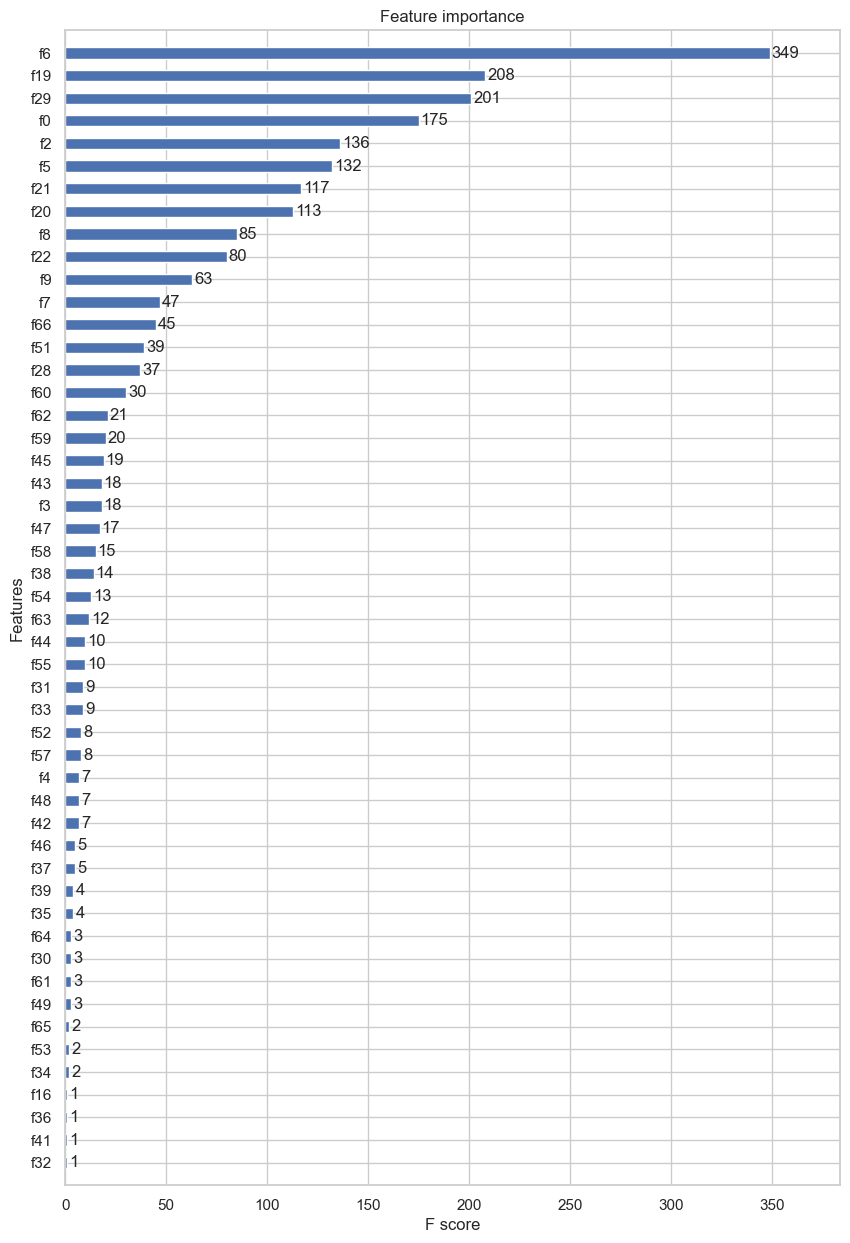

In [94]:
import matplotlib.pyplot as plt
from xgboost import plot_importance
fig,ax = plt.subplots(figsize=(10,15))
plot_importance(grid_xgbt_model,height=0.5,max_num_features=64,ax=ax)
plt.show()

# 模型融合

单模型具有各自的优势和劣势，将不同模型的结果进行一定程度的集成一般能得到更好的效果。

### 均值融合

In [95]:
# 决策树分类器的预测结果
y_pred_dt

array([0.90338164, 0.03117506, 0.        , ..., 1.        , 1.        ,
       0.5625    ])

In [96]:
# 逻辑回归的预测结果
y_pred_LogisticReg

array([0.70666373, 0.0441459 , 0.89026159, ..., 0.85540963, 0.96283276,
       0.48736696])

In [97]:
# 将两种模型的结果组合起来
combine_result = pd.DataFrame({'dt_pred_result':y_pred_dt,
                               'log_pred_result':y_pred_LogisticReg})

In [98]:
# 将结果求平均值
combine_pred = combine_result.mean(axis = 1)

In [99]:
roc_auc_score(y_test, combine_pred)

0.9016070100559382

### Stacking

In [100]:
from sklearn.linear_model import LinearRegression

In [101]:
# 将两种模型的结果组合起来
combine_result = pd.DataFrame({'dt_pred_result':y_pred_dt,
                               'log_pred_result':y_pred_LogisticReg,
                                'y_true_value':y_test})

In [102]:
# 线性回归的X
col = ['dt_pred_result','log_pred_result']
X_stacking = combine_result[col].reset_index(drop = True)
X_stacking = X_stacking.values
X_stacking

array([[0.90338164, 0.70666373],
       [0.03117506, 0.0441459 ],
       [0.        , 0.89026159],
       ...,
       [1.        , 0.85540963],
       [1.        , 0.96283276],
       [0.5625    , 0.48736696]])

In [103]:
# 线性回归的y
y_stacking = combine_result['y_true_value'].reset_index(drop = True)
y_stacking = y_stacking.values
y_stacking

array([1, 0, 0, ..., 1, 1, 1])

In [104]:
# 拟合
reg = LinearRegression().fit(X_stacking,y_stacking)

In [105]:
# 得到的权重
reg.coef_

array([0.40024115, 0.64823371])

In [106]:
# 根据线性回归模型做的stacking权重得到最后的预测结果
y_combine_result = reg.predict(X_stacking)

In [107]:
roc_auc_score(y_test, y_combine_result)

0.9047757622789147